# Mathematics: Convex Optimization and Duality

> **Who is this for:** you know gradient descent from [`06_optimization`](06_optimization.ipynb) and now want the theory that MS-level machine learning, operations research and optimisation courses expect: what makes a problem *convex*, what the *dual* of a problem is, what the **KKT conditions** say, and how the solvers behind Lasso, SVMs and portfolio tools actually work. It is also for interview preparation ("derive the SVM dual", "why does Lasso give zeros?").
>
> **What you will learn:**
> - **Convex sets and convex functions**, with two checkers written from scratch (a chord test and a Hessian test), and the operations that keep a function convex
> - The four standard problem forms, **LP, QP, SOCP and SDP**, each solved on a tiny example with scipy (and, if it is installed, the modelling library **cvxpy**)
> - The **Lagrangian**, the **dual function**, **weak and strong duality**, **Slater's condition**, and examples where the duality gap is zero, positive, or where the dual optimum is never attained
> - The **KKT conditions**, solved by hand and checked by a tiny QP solver written from scratch
> - The **SVM dual** derived and solved as a QP, compared with scikit-learn's `SVC`
> - Three first-order algorithms from scratch: **projected gradient descent**, **proximal gradient (ISTA / FISTA)** for Lasso, and **ADMM** (including a consensus version that is the core idea of federated optimisation)
> - **Interior-point methods**, through a barrier method on a 2-D linear program with its *central path* drawn
> - Applications: a fairness constraint, a portfolio QP, and a demonstration that neural-network training is **not** convex
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb); [linear algebra](01_linear_algebra.ipynb) (eigenvalues, positive semidefinite matrices); [calculus](02_calculus.ipynb) (gradients, Hessians); [optimisation](06_optimization.ipynb) (gradient descent, Lagrange multipliers). Linear-programming duality from scratch is in [`advanced_algorithms/05`](../00_AI_Fundamentals/advanced_algorithms/05_linear_and_integer_programming.ipynb); we do not repeat it.
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about 1–2 minutes. `cvxpy` is optional: cells that use it print a one-line message and skip if it is not installed.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Boyd & Vandenberghe, *Convex Optimization* (chapters 2–5, 9–11), the standard text for CMU 10-725 and Stanford EE364A.

## Explained simply

Optimisation means finding the best choice: the cheapest route, the most accurate model, the safest investment. A problem is **convex** when its "landscape" is shaped like a single bowl, with no false valleys. In a bowl, if you keep walking downhill you are guaranteed to reach the very bottom. In a mountain range (a non-convex problem) you might get stuck in a small dip and never find the deepest valley.

Most real problems also have **rules** (constraints): a budget, a speed limit, "weights must add up to 1". **Duality** looks at the same problem from the other side: instead of asking "what is the best plan that obeys the rules?", it asks "how much would I pay to bend each rule a little?". Those prices are called **Lagrange multipliers**. For convex problems both views give the same answer, which lets us prove that a solution is truly the best.

Two everyday pictures:
- **A marble in a salad bowl** always rolls to the same lowest point, wherever you drop it. That is a convex problem. A marble on an egg carton can get stuck in any of the twelve cups. That is a non-convex problem, like training a neural network.
- **A shop owner with limited shelf space** can ask "what is the best mix of products?" (the primal problem) or "how much extra profit would one more shelf bring me?" (the dual problem). That extra profit is the "price" of the shelf constraint.

**Tiny example.** Find the smallest $x^2$ when the rule says $x \ge 1$. Without the rule the answer would be $x = 0$, but the rule pushes us to $x = 1$, so the best value is $1^2 = 1$. The "price" of the rule is 2: if the rule were $x \ge 1.1$, the best value would become $1.1^2 = 1.21$, which is about $2 \times 0.1 = 0.2$ more. You will see this number 2 appear as the Lagrange multiplier in Section 3.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Convex problem | a single-bowl landscape, so going downhill always finds the best answer | linear/logistic regression, SVMs, Lasso, portfolio planning |
| Duality / Lagrange multiplier | the "price" of each rule, and a second view of the same problem | SVM support vectors, shadow prices in supply chains, constrained RL |
| Proximal / ADMM / interior-point methods | recipes that solve big convex problems with rules quickly | Lasso solvers, federated learning, the solvers inside cvxpy and Gurobi |

### How this notebook is different from `06_optimization`
[`06_optimization`](06_optimization.ipynb) is a tour of the optimisers used to train neural networks (SGD, momentum, Adam, schedules) and mentions Lagrange multipliers and KKT in a few lines of text. This notebook is the *theory and algorithms of constrained convex optimisation*: we prove things about optimal solutions, compute dual problems and multipliers numerically, and write the algorithms that solve problems with constraints and non-smooth terms (an $\ell_1$ penalty, a box, a simplex).

## Table of contents
1. Convex sets and convex functions
2. Standard problem forms: LP, QP, SOCP, SDP
3. The Lagrangian, the dual function and duality
4. The KKT conditions
5. The SVM dual as a quadratic program
6. Projected gradient descent
7. Proximal gradient: ISTA and FISTA for Lasso
8. ADMM: Lasso and consensus (distributed) optimisation
9. Interior-point methods: the barrier method and the central path
10. Applications: fairness constraints, portfolios, and why deep learning is non-convex
11. Summary table of algorithms
12. How this connects to modern AI
13. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from scipy.optimize import minimize, linprog, nnls
from sklearn.svm import SVC
from sklearn.linear_model import Lasso
from sklearn.datasets import make_blobs
import itertools, warnings

rng = np.random.default_rng(0)        # NumPy's modern random generator, seeded

# cvxpy is an optional modelling library: everything below also works without it.
try:
    import cvxpy as cp
    HAVE_CVXPY = True
    print("cvxpy", cp.__version__, "is available; solvers:", cp.installed_solvers())
except ImportError:
    HAVE_CVXPY = False
    print("cvxpy is not installed: cvxpy cells will skip (pip install cvxpy to enable them).")

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


cvxpy is not installed: cvxpy cells will skip (pip install cvxpy to enable them).


## 1. Convex sets and convex functions

> 💬 **In plain English:** a convex problem is a single bowl, so we first learn to recognise bowls (convex sets and functions).

### 1.1 Convex sets

A set $C$ is a **convex set** if the straight line segment between any two of its points stays inside it:

$$x, y \in C,\; \theta \in [0, 1] \;\Rightarrow\; \theta x + (1-\theta) y \in C.$$

The point $\theta x + (1-\theta)y$ is called a **convex combination** of $x$ and $y$.

| Set | Convex? | Why |
|---|---|---|
| a disk, a ball $\{x : \lVert x\rVert \le r\}$ (any norm) | yes | the triangle inequality |
| a half-space $\{x : a^\top x \le b\}$ | yes | a linear inequality is preserved by averaging |
| a polygon / polyhedron $\{x : Ax \le b\}$ | yes | an intersection of half-spaces, and **intersections of convex sets are convex** |
| a ring (annulus) $\{x : 0.5 \le \lVert x\rVert \le 1\}$ | no | the segment between opposite points passes through the hole |
| the union of two separate disks | no | the segment between the disks leaves the set |

Hand example for the ring: take $x = (0.75, 0)$ and $y = (-0.75, 0)$. Both have norm 0.75, so both are in the ring. Their midpoint ($\theta = 0.5$) is $(0, 0)$, with norm 0 < 0.5, so it is outside. One counterexample is enough to prove "not convex".

The checker below cannot *prove* convexity (no finite number of tests can), but it can *find counterexamples*: it samples pairs of points in the set and tests random convex combinations.

disk  ||x|| <= 1             -> no counterexample: convex


triangle (3 half-planes)     -> no counterexample: convex


L1 ball |x1|+|x2| <= 1       -> no counterexample: convex


ring 0.5 <= ||x|| <= 1       -> NOT convex (x = outside point)


two disks (union)            -> NOT convex (x = outside point)


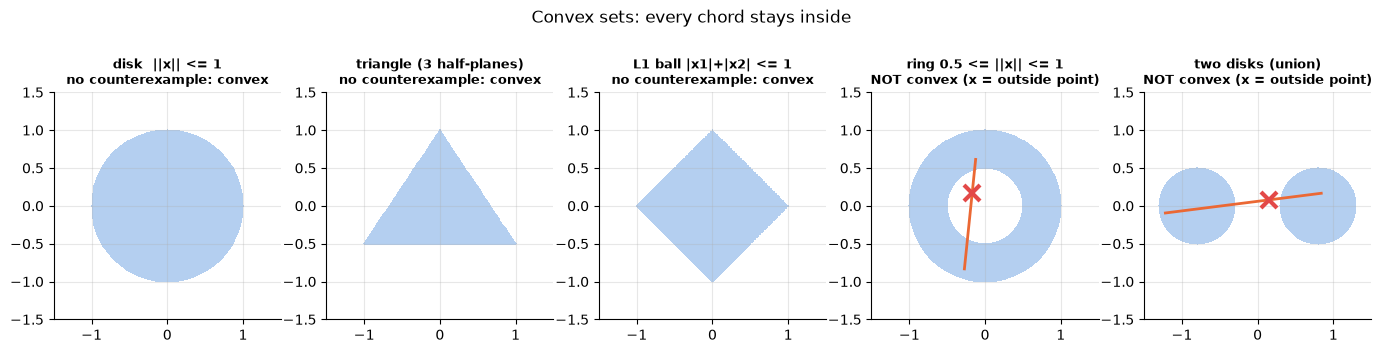

In [2]:
def find_nonconvex_witness(member, trials=20000, box=1.5, seed=0):
    """Search for points a, b in the set and theta in [0,1] such that the
    convex combination theta*a + (1-theta)*b is NOT in the set.
    Returns (a, b, theta) if found, otherwise None (= no counterexample found)."""
    r = np.random.default_rng(seed)
    pts = r.uniform(-box, box, size=(trials, 2))           # random candidate points
    inside = pts[[member(p) for p in pts]]                  # keep those inside the set
    for _ in range(trials):
        a, b = inside[r.integers(len(inside))], inside[r.integers(len(inside))]
        theta = r.random()
        if not member(theta * a + (1 - theta) * b):         # left the set: not convex
            return a, b, theta
    return None

sets = {
    "disk  ||x|| <= 1":           lambda p: np.linalg.norm(p) <= 1,
    "triangle (3 half-planes)":   lambda p: p[1] >= -0.5 and p[1] <= 1 - 1.5 * abs(p[0]) ,
    "L1 ball |x1|+|x2| <= 1":     lambda p: abs(p[0]) + abs(p[1]) <= 1,
    "ring 0.5 <= ||x|| <= 1":     lambda p: 0.5 <= np.linalg.norm(p) <= 1,
    "two disks (union)":          lambda p: np.linalg.norm(p - [-0.8, 0]) <= 0.5 or np.linalg.norm(p - [0.8, 0]) <= 0.5,
}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
grid = np.linspace(-1.5, 1.5, 241)
G1, G2 = np.meshgrid(grid, grid)
for ax, (name, member) in zip(axes, sets.items()):
    mask = np.array([[member(np.array([u, v])) for u in grid] for v in grid])
    ax.contourf(G1, G2, mask, levels=[0.5, 1.5], colors=[PALETTE[0]], alpha=0.35)
    w = find_nonconvex_witness(member)
    if w is None:
        verdict = "no counterexample: convex"
    else:
        a, b, th = w
        c = th * a + (1 - th) * b
        ax.plot([a[0], b[0]], [a[1], b[1]], "-", color=PALETTE[1])
        ax.plot(*c, "x", color=PALETTE[7], ms=12, mew=3)
        verdict = "NOT convex (x = outside point)"
    ax.set_title(f"{name}\n{verdict}", fontsize=9)
    ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
    print(f"{name:28s} -> {verdict}")
plt.suptitle("Convex sets: every chord stays inside", y=1.04)
plt.show()

**What just happened?** For the disk, the triangle and the $\ell_1$ ball, 20,000 random chords all stayed inside, as the theory says. For the ring and the two disks the search found a chord (orange) whose point marked with a red cross falls outside: a certificate that the set is not convex.

### 1.2 Convex functions

A function $f$ is a **convex function** if its domain is a convex set and the chord between any two points on its graph lies on or above the graph (**Jensen's inequality**):

$$f(\theta x + (1-\theta)y) \;\le\; \theta f(x) + (1-\theta) f(y) \quad \text{for all } x, y,\ \theta \in [0,1].$$

It is **strictly convex** if the inequality is strict whenever $x \ne y$ and $0 < \theta < 1$, and **concave** if $-f$ is convex. Two equivalent tests for twice-differentiable functions:

- **First-order condition:** $f(y) \ge f(x) + \nabla f(x)^\top (y - x)$. The tangent plane is a global under-estimator. This is why, for a convex function, $\nabla f(x^\star) = 0$ means $x^\star$ is a **global** minimum.
- **Second-order condition:** the **Hessian** $\nabla^2 f(x)$ is **positive semidefinite** (PSD: all eigenvalues $\ge 0$) everywhere on the domain.

Worked example by hand: $f(x, y) = xy$. Its Hessian is $\begin{pmatrix}0 & 1\\ 1 & 0\end{pmatrix}$ with eigenvalues $+1$ and $-1$, so it is not PSD and $f$ is not convex (it is a saddle). In contrast $f(x) = e^x$ has $f''(x) = e^x > 0$, so it is (strictly) convex.

Below we implement both tests numerically: a random chord test (Jensen) and a finite-difference Hessian test.

In [3]:
def jensen_violations(f, sample, trials=5000, seed=1):
    """Count random (x, y, theta) for which Jensen's inequality fails."""
    r = np.random.default_rng(seed)
    bad = 0
    for _ in range(trials):
        x, y, th = sample(r), sample(r), r.random()
        lhs = f(th * x + (1 - th) * y)
        rhs = th * f(x) + (1 - th) * f(y)
        bad += lhs > rhs + 1e-9                     # small tolerance for rounding
    return int(bad)

def numerical_hessian(f, x, h=1e-4):
    """Central finite-difference Hessian of f at x (x is a 1-D array)."""
    d = len(x)
    H = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            ei, ej = np.eye(d)[i] * h, np.eye(d)[j] * h
            H[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * h * h)
    return (H + H.T) / 2                              # symmetrise away rounding noise

def min_hessian_eig(f, sample, points=300, seed=2):
    """Smallest Hessian eigenvalue over random points (>= 0 everywhere means PSD)."""
    r = np.random.default_rng(seed)
    return min(np.linalg.eigvalsh(numerical_hessian(f, sample(r))).min() for _ in range(points))

real = lambda lo, hi, d: (lambda r: r.uniform(lo, hi, size=d))   # sampler factory

candidates = [
    ("x^2",                 lambda v: v[0] ** 2,                        real(-3, 3, 1)),
    ("exp(x)",              lambda v: np.exp(v[0]),                     real(-3, 3, 1)),
    ("x^3",                 lambda v: v[0] ** 3,                        real(-3, 3, 1)),
    ("-log(x), x>0",        lambda v: -np.log(v[0]),                    real(0.1, 5, 1)),
    ("log-sum-exp(x1,x2)",  lambda v: np.log(np.exp(v).sum()),          real(-3, 3, 2)),
    ("x1 * x2",             lambda v: v[0] * v[1],                      real(-3, 3, 2)),
    ("x1^2 + 3 x2^2 + x1 x2", lambda v: v[0]**2 + 3*v[1]**2 + v[0]*v[1], real(-3, 3, 2)),
    ("sin(x)",              lambda v: np.sin(v[0]),                     real(-3, 3, 1)),
]
rows = []
for name, f, s in candidates:
    viol = jensen_violations(f, s)
    lam_min = min_hessian_eig(f, s)
    rows.append({"function": name, "Jensen violations / 5000": viol,
                 "min Hessian eigenvalue": round(lam_min, 4),
                 "verdict": "convex" if viol == 0 and lam_min > -1e-4 else "NOT convex"})
convexity_table = pd.DataFrame(rows)
convexity_table

,function,Jensen violations / 5000,min Hessian eigenvalue,verdict
0,x^2,0,2.0000,convex
1,exp(x),0,0.0507,convex
2,x^3,2545,-17.8853,NOT convex
3,"-log(x), x>0",0,0.0409,convex
4,"log-sum-exp(x1,x2)",0,-0.0000,convex
5,x1 * x2,2540,-1.0000,NOT convex
6,x1^2 + 3 x2^2 + x1 x2,0,1.7639,convex
7,sin(x),2452,-0.9997,NOT convex


**What just happened?** Both tests agree on every function. $x^3$, $\sin x$ and $x_1 x_2$ fail: the chord test finds violations and the Hessian has negative eigenvalues somewhere. Log-sum-exp is convex, but its minimum Hessian eigenvalue is $0$ (up to rounding): it is flat along the direction $(1, 1)$, because adding a constant to both inputs adds the same constant to the output. A Hessian that is PSD but not positive definite means "convex but not strictly convex".

⚠️ **Common mistake:** "the Hessian is positive at the point I checked, so $f$ is convex". The condition must hold **on the whole domain**. $x^3$ has $f''(1) = 6 > 0$ but $f''(-1) = -6 < 0$.

### 1.3 Operations that preserve convexity

Checking the Hessian by hand is slow. In practice we build convex functions from simple ones using rules that keep convexity (this is exactly what cvxpy's "disciplined convex programming" checks automatically):

| Operation | Rule | Example |
|---|---|---|
| non-negative weighted sum | $f, g$ convex, $a, b \ge 0$ ⇒ $af + bg$ convex | loss + $\lambda \cdot$ regulariser |
| affine composition | $f$ convex ⇒ $f(Ax + b)$ convex | $\lVert Xw - y \rVert^2$ |
| pointwise maximum | $f_1, \dots, f_k$ convex ⇒ $\max_i f_i$ convex | hinge loss $\max(0, 1 - y w^\top x)$ |
| composition | $h$ convex and non-decreasing, $g$ convex ⇒ $h(g(x))$ convex | $e^{\lVert x\rVert^2}$ |
| partial minimisation | $f(x, y)$ jointly convex ⇒ $\min_y f(x, y)$ convex | distance to a convex set |

Not preserved: **differences** ($x^2 - 2|x|$ is not convex), **products** ($x \cdot x^2 = x^3$), and **minimum** of convex functions.

In [4]:
s1 = real(-3, 3, 1)
checks = {
    "2*x^2 + 3*exp(x)          (weighted sum)":       lambda v: 2 * v[0]**2 + 3 * np.exp(v[0]),
    "(2x - 1)^4                (affine composition)": lambda v: (2 * v[0] - 1) ** 4,
    "max(0, 1 - 2x)  hinge     (pointwise max)":      lambda v: max(0.0, 1 - 2 * v[0]),
    "exp(x^2)                  (composition)":        lambda v: np.exp(v[0] ** 2),
    "x^2 - 2|x|                (difference)":         lambda v: v[0]**2 - 2 * abs(v[0]),
    "min((x-1)^2, (x+1)^2)     (minimum)":            lambda v: min((v[0] - 1)**2, (v[0] + 1)**2),
}
for name, f in checks.items():
    print(f"{name:50s} Jensen violations: {jensen_violations(f, s1):5d}")

2*x^2 + 3*exp(x)          (weighted sum)           Jensen violations:     0
(2x - 1)^4                (affine composition)     Jensen violations:     0
max(0, 1 - 2x)  hinge     (pointwise max)          Jensen violations:     0


exp(x^2)                  (composition)            Jensen violations:     0
x^2 - 2|x|                (difference)             Jensen violations:   715
min((x-1)^2, (x+1)^2)     (minimum)                Jensen violations:   715


**What just happened?** The four functions built with the rules have zero violations. The difference and the minimum of two convex functions have many: both have *two* separate valleys (at $x = \pm 1$), the hallmark of non-convexity.

🎓 **Exam / interview tip:** "Is the logistic-regression loss convex?" Yes: $\log(1 + e^{-y w^\top x})$ is log-sum-exp of $(0, -y w^\top x)$, which is convex, composed with an affine function of $w$. Summing over data points keeps it convex. The same argument fails for a neural network because the model output is not affine in the weights.

## 2. Standard problem forms: LP, QP, SOCP, SDP

> 💬 **In plain English:** most convex problems you will meet are one of four standard shapes, and each has a fast solver.

A **convex optimisation problem** in standard form is

$$\begin{aligned} \min_x \; & f_0(x) \\ \text{s.t. } & f_i(x) \le 0,\; i = 1, \dots, m \quad (f_i \text{ convex})\\ & Ax = b \quad (\text{equality constraints must be affine}) \end{aligned}$$

Its key property: **every local minimum is a global minimum**, and the set of minimisers is convex. Most convex problems met in practice fall into a hierarchy of standard forms, each more general than the last:

| Form | Objective | Constraints | Example in ML / AI |
|---|---|---|---|
| **LP** linear program | $c^\top x$ | $Ax \le b$ | L1 regression, optimal transport, scheduling |
| **QP** quadratic program | $\tfrac12 x^\top P x + q^\top x$, $P \succeq 0$ | $Ax \le b$ | SVM, Lasso (rewritten), portfolio, MPC control |
| **SOCP** second-order cone program | $c^\top x$ | $\lVert A_i x + b_i\rVert_2 \le c_i^\top x + d_i$ | robust LP, facility location, group Lasso |
| **SDP** semidefinite program | $c^\top x$ | $F_0 + \sum_i x_i F_i \succeq 0$ (a matrix is PSD) | max-cut relaxation, covariance estimation, control |

LP ⊂ QP ⊂ SOCP ⊂ SDP: each form can be rewritten as the next one. Below we solve one tiny problem of each kind with scipy (or a from-scratch method), and then the same four problems in cvxpy if it is installed.

In [5]:
# --- LP: maximise 3x + 2y  s.t.  x + y <= 4,  x + 3y <= 6,  x, y >= 0  (linprog minimises, so negate)
lp = linprog(c=[-3, -2], A_ub=[[1, 1], [1, 3]], b_ub=[4, 6], bounds=[(0, None)] * 2, method="highs")
print("LP  :  x* =", lp.x, " objective =", -lp.fun)

# --- QP: min 1/2 x^T P x + q^T x  s.t.  x1 + x2 >= 1, x >= 0
P = np.array([[2.0, 0.5], [0.5, 1.0]]); q = np.array([-1.0, 0.0])
qp = minimize(lambda x: 0.5 * x @ P @ x + q @ x, x0=[1.0, 1.0], jac=lambda x: P @ x + q,
              bounds=[(0, None)] * 2, constraints=[{"type": "ineq", "fun": lambda x: x[0] + x[1] - 1}],
              method="SLSQP", options={"ftol": 1e-12})
print("QP  :  x* =", qp.x.round(6), " objective =", round(qp.fun, 6))

# --- SOCP: Fermat-Weber facility location  min_x  sum_i ||x - p_i||_2
#     (put a warehouse where the total straight-line distance to 5 shops is smallest)
shops = np.array([[0, 0], [4, 0], [4, 3], [1, 4], [0, 2]], dtype=float)
def weiszfeld(points, iters=500):
    """Classic fixed-point algorithm for the geometric median (from scratch)."""
    x = points.mean(axis=0)                                   # start at the centroid
    for _ in range(iters):
        d = np.linalg.norm(points - x, axis=1)
        d = np.maximum(d, 1e-12)                              # avoid dividing by zero
        x = (points / d[:, None]).sum(0) / (1 / d).sum()      # distance-weighted average
    return x
x_fw = weiszfeld(shops)
check = minimize(lambda x: np.linalg.norm(shops - x, axis=1).sum(), x0=[0, 0], method="Nelder-Mead",
                 options={"xatol": 1e-10, "fatol": 1e-10})
print("SOCP:  Weiszfeld x* =", x_fw.round(5), " Nelder-Mead x* =", check.x.round(5),
      " total distance =", round(np.linalg.norm(shops - x_fw, axis=1).sum(), 5))

# --- SDP: lambda_max(A) = min t  s.t.  t*I - A is PSD.  Solve by bisection on t + a PSD test.
def is_psd(M):
    """A symmetric matrix is PSD iff M + tiny*I has a Cholesky factorisation."""
    try:
        np.linalg.cholesky(M + 1e-12 * np.eye(len(M)))
        return True
    except np.linalg.LinAlgError:
        return False
A_sym = rng.normal(size=(5, 5)); A_sym = (A_sym + A_sym.T) / 2
lo, hi = -10.0, 10.0
for _ in range(60):                                           # bisection: 60 halvings
    mid = (lo + hi) / 2
    lo, hi = (lo, mid) if is_psd(mid * np.eye(5) - A_sym) else (mid, hi)
print("SDP:  bisection t* =", round(hi, 8), "  numpy largest eigenvalue =", round(np.linalg.eigvalsh(A_sym).max(), 8))

LP  :  x* = [4. 0.]  objective = 12.0
QP  :  x* = [0.75 0.25]  objective = -0.0625


SOCP:  Weiszfeld x* = [1.34693 1.93278]  Nelder-Mead x* = [1.34693 1.93278]  total distance = 11.94267
SDP:  bisection t* = 2.04841795   numpy largest eigenvalue = 2.04841795


In [6]:
# The same four problems written in cvxpy (optional). cvxpy checks convexity with its DCP rules
# and hands each problem to a suitable solver (HiGHS/Clarabel/OSQP/SCS).
if HAVE_CVXPY:
    x = cp.Variable(2)
    p_lp = cp.Problem(cp.Maximize(3 * x[0] + 2 * x[1]), [x[0] + x[1] <= 4, x[0] + 3 * x[1] <= 6, x >= 0])
    p_lp.solve();  print("cvxpy LP  :", x.value.round(4), round(p_lp.value, 4))
    x = cp.Variable(2)
    p_qp = cp.Problem(cp.Minimize(0.5 * cp.quad_form(x, P) + q @ x), [cp.sum(x) >= 1, x >= 0])
    p_qp.solve();  print("cvxpy QP  :", x.value.round(4), round(p_qp.value, 4))
    x = cp.Variable(2)
    p_soc = cp.Problem(cp.Minimize(sum(cp.norm(x - s, 2) for s in shops)))
    p_soc.solve(); print("cvxpy SOCP:", x.value.round(4), round(p_soc.value, 4))
    t = cp.Variable()
    p_sdp = cp.Problem(cp.Minimize(t), [t * np.eye(5) - A_sym >> 0])     # '>> 0' means PSD
    p_sdp.solve(); print("cvxpy SDP :", round(float(t.value), 5))
else:
    print("cvxpy not installed: skipping the cvxpy versions (the scipy results above are the reference).")

cvxpy not installed: skipping the cvxpy versions (the scipy results above are the reference).


**What just happened?** Each solver agrees with its check:
- The LP optimum is at the vertex $(4, 0)$, as LP optima always are (see [`advanced_algorithms/05`](../00_AI_Fundamentals/advanced_algorithms/05_linear_and_integer_programming.ipynb)).
- The QP has the constraint $x_1 + x_2 \ge 1$ active.
- The Weiszfeld fixed-point iteration and a derivative-free optimiser agree on the facility location.
- Bisection with a Cholesky "is it PSD?" test reproduces the largest eigenvalue to 8 decimals. This SDP has a closed-form answer, which is why it makes a good test.

**Complexity:** general-purpose interior-point solvers need roughly 10–50 Newton steps, each costing about $O(n^3)$ for $n$ variables (dense linear algebra). This is why first-order methods (Sections 6–8) are used when $n$ is in the millions.

## 3. The Lagrangian, the dual function and duality

> 💬 **In plain English:** every constrained problem has a twin, the dual, which puts a price on each rule and gives a lower bound on the best possible value.

For the problem $\min f_0(x)$ s.t. $f_i(x) \le 0$ ($i = 1..m$), $h_j(x) = 0$ ($j = 1..p$), the **Lagrangian** adds each constraint to the objective with a weight (a **Lagrange multiplier**, or dual variable):

$$L(x, \lambda, \nu) = f_0(x) + \sum_{i=1}^m \lambda_i f_i(x) + \sum_{j=1}^p \nu_j h_j(x), \qquad \lambda \ge 0.$$

The **Lagrange dual function** is the best value of the Lagrangian over $x$ with no constraints:

$$g(\lambda, \nu) = \inf_x L(x, \lambda, \nu).$$

It has two key properties:
- It is always **concave**, because it is a pointwise infimum of affine functions of $(\lambda, \nu)$. This holds even when the original problem is not convex.
- **Weak duality:** $g(\lambda, \nu) \le p^\star$ for every $\lambda \ge 0$, where $p^\star$ is the optimal value. Proof: for any feasible $x$, $f_i(x) \le 0$ and $\lambda_i \ge 0$, so $L(x, \lambda, \nu) \le f_0(x)$. Then $g$, the infimum over all $x$, is at most $f_0(x)$ for every feasible $x$.

The **dual problem** is $d^\star = \max_{\lambda \ge 0, \nu} g(\lambda, \nu)$. We always have $d^\star \le p^\star$, and $p^\star - d^\star$ is the **duality gap**. **Strong duality** means $d^\star = p^\star$. For convex problems it holds under **Slater's condition**: there is a strictly feasible point, i.e. one with $f_i(x) < 0$ for all non-affine $f_i$ (affine inequalities only need to be satisfied, not strictly).

### Worked example by hand: $\min x^2$ s.t. $x \ge 1$

Write the constraint as $f_1(x) = 1 - x \le 0$.

| Step | Computation |
|---|---|
| Lagrangian | $L(x, \lambda) = x^2 + \lambda (1 - x)$ |
| minimise over $x$ | $\partial L / \partial x = 2x - \lambda = 0 \Rightarrow x = \lambda / 2$ |
| dual function | $g(\lambda) = \lambda^2/4 + \lambda - \lambda^2/2 = \lambda - \lambda^2 / 4$ |
| dual problem | $\max_{\lambda \ge 0} \lambda - \lambda^2/4 \Rightarrow \lambda^\star = 2,\; d^\star = 1$ |
| primal | $x^\star = 1,\; p^\star = 1$, so the gap is $0$ (Slater holds: $x = 2$ is strictly feasible) |

The multiplier $\lambda^\star = 2$ is the "price" from the *Explained simply* section: $\frac{d p^\star}{d b} = 2b = 2$ at $b = 1$ for the constraint $x \ge b$. This is the **sensitivity interpretation**: $\lambda_i^\star$ is how fast the optimal value changes when constraint $i$ is loosened or tightened.

A: min x^2  s.t. x >= 1  (convex, Slater holds)
   p* = 1.0000, d* = 1.0000, duality gap = 0.0000, lambda* = 2.00


B: min (x^2-1)^2 + 0.3x  s.t. x >= 0  (NON-convex objective)
   p* = 0.2941, d* = 0.0000, duality gap = 0.2941, lambda* = 0.30


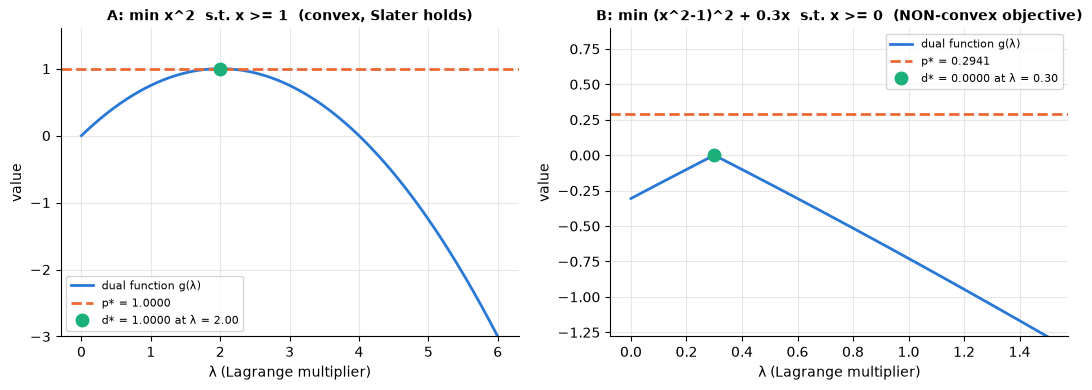

In [7]:
def dual_numeric(f0, f1, xs, lams):
    """g(lambda) = min over a fine x-grid of f0(x) + lambda * f1(x)  (one inequality constraint)."""
    return np.array([np.min(f0(xs) + l * f1(xs)) for l in lams])

xs = np.linspace(-5, 5, 200001)                    # fine grid stands in for 'inf over all x'
examples = {
    "A: min x^2  s.t. x >= 1  (convex, Slater holds)":
        (lambda x: x**2, lambda x: 1 - x, np.linspace(0, 6, 1201)),
    "B: min (x^2-1)^2 + 0.3x  s.t. x >= 0  (NON-convex objective)":
        (lambda x: (x**2 - 1)**2 + 0.3 * x, lambda x: -x, np.linspace(0, 1.5, 1501)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, (f0, f1, lams)) in zip(axes, examples.items()):
    feas = f1(xs) <= 0
    p_star = f0(xs[feas]).min()                    # primal optimum by brute force
    g = dual_numeric(f0, f1, xs, lams)
    d_star, lam_star = g.max(), lams[g.argmax()]
    ax.plot(lams, g, label="dual function g(λ)")
    ax.axhline(p_star, color=PALETTE[1], ls="--", label=f"p* = {p_star:.4f}")
    ax.plot(lam_star, d_star, "o", color=PALETTE[2], ms=9, label=f"d* = {d_star:.4f} at λ = {lam_star:.2f}")
    ax.set_xlabel("λ (Lagrange multiplier)"); ax.set_ylabel("value"); ax.set_title(name, fontsize=10)
    ax.set_ylim(max(g.min(), -3), p_star + 0.6 * max(1, p_star)); ax.legend(fontsize=8)
    print(f"{name}\n   p* = {p_star:.4f}, d* = {d_star:.4f}, duality gap = {p_star - d_star:.4f}, lambda* = {lam_star:.2f}")
plt.show()

**What just happened?**
- **Example A** reproduces the hand calculation: the dual function is the concave parabola $\lambda - \lambda^2/4$, it never rises above $p^\star$ (weak duality), and it touches $p^\star = 1$ at $\lambda^\star = 2$ (strong duality).
- **Example B** has a double-well objective. Its global minimum is in the forbidden region $x < 0$, and the best allowed point is near $x \approx 0.96$ with $p^\star \approx 0.294$. The dual is still concave and still a lower bound, but its maximum is $d^\star = 0$: a **positive duality gap** of about $0.294$. At $\lambda = 0.3$ the penalty $-0.3x$ exactly cancels the $+0.3x$ term, so the Lagrangian is just $(x^2-1)^2$, whose minimum value $0$ is reached at $x = \pm 1$, including the infeasible point $x = -1$. No single price can make the Lagrangian's minimiser feasible, because the objective is not convex.

### When the dual optimum is not attained (Slater fails)

Consider $\min x$ s.t. $x^2 \le 0$. The only feasible point is $x = 0$, so $p^\star = 0$, and there is **no strictly feasible point**: Slater fails. The Lagrangian $x + \lambda x^2$ has minimiser $x = -1/(2\lambda)$, giving $g(\lambda) = -1/(4\lambda)$. As $\lambda \to \infty$, $g(\lambda) \to 0 = p^\star$, so the gap is zero, but **no finite $\lambda$ reaches it**. We will see in Section 4 that the KKT conditions then have no solution.

In [8]:
for lam in [1, 10, 100, 1e4, 1e6]:
    print(f"lambda = {lam:>9g}:  g(lambda) = -1/(4 lambda) = {-1 / (4 * lam):.2e}   (approaches p* = 0 but never reaches it)")

lambda =         1:  g(lambda) = -1/(4 lambda) = -2.50e-01   (approaches p* = 0 but never reaches it)
lambda =        10:  g(lambda) = -1/(4 lambda) = -2.50e-02   (approaches p* = 0 but never reaches it)
lambda =       100:  g(lambda) = -1/(4 lambda) = -2.50e-03   (approaches p* = 0 but never reaches it)
lambda =     10000:  g(lambda) = -1/(4 lambda) = -2.50e-05   (approaches p* = 0 but never reaches it)
lambda =     1e+06:  g(lambda) = -1/(4 lambda) = -2.50e-07   (approaches p* = 0 but never reaches it)


## 4. The KKT conditions

The KKT conditions are a checklist that the optimal point and its "prices" must pass. For a convex problem they are also enough to prove a point is optimal.

For differentiable $f_0, f_i, h_j$, the **Karush–Kuhn–Tucker (KKT) conditions** at a point $x^\star$ with multipliers $\lambda^\star, \nu^\star$ are:

| # | Name | Condition |
|---|---|---|
| 1 | primal feasibility | $f_i(x^\star) \le 0$, $h_j(x^\star) = 0$ |
| 2 | dual feasibility | $\lambda^\star_i \ge 0$ |
| 3 | **complementary slackness** | $\lambda^\star_i f_i(x^\star) = 0$ for every $i$ (a constraint is either tight, or its price is zero) |
| 4 | stationarity | $\nabla f_0(x^\star) + \sum_i \lambda^\star_i \nabla f_i(x^\star) + \sum_j \nu^\star_j \nabla h_j(x^\star) = 0$ |

Theorems to remember:
- If strong duality holds, every primal-dual optimal pair satisfies KKT (KKT is **necessary**).
- For a **convex** problem, any point satisfying KKT is optimal (KKT is **sufficient**).
- So for a convex problem with Slater's condition, **KKT ⇔ optimal**.

### Worked example by hand

$\min (x-2)^2 + (y-1)^2$ s.t. $g_1: x + y \le 2$, $g_2: -x \le 0$.

1. The unconstrained minimum $(2, 1)$ violates $g_1$ ($2 + 1 = 3 > 2$), so guess that $g_1$ is active and $g_2$ is inactive ($\lambda_2 = 0$).
2. Stationarity: $2(x - 2) + \lambda_1 = 0$ and $2(y - 1) + \lambda_1 = 0$, so $x - 2 = y - 1$, i.e. $x = y + 1$.
3. Active constraint: $x + y = 2 \Rightarrow y = 0.5,\ x = 1.5$.
4. Then $\lambda_1 = -2(1.5 - 2) = 1 \ge 0$ ✓, and $g_2$: $-1.5 < 0$ ✓ (inactive, so $\lambda_2 = 0$ is consistent).

So $x^\star = (1.5, 0.5)$ with $\lambda^\star = (1, 0)$ and $p^\star = 0.25 + 0.25 = 0.5$.

### A tiny QP solver from scratch: try every active set

"Guess which constraints are active" can be automated for small problems. For a QP $\min \tfrac12 x^\top P x + q^\top x$ s.t. $Gx \le h$, $Ax = b$, pick a subset $S$ of inequality constraints to be active. Then stationarity plus the active constraints form one **linear** system:

$$\begin{pmatrix} P & G_S^\top & A^\top \\ G_S & 0 & 0 \\ A & 0 & 0\end{pmatrix}\begin{pmatrix} x \\ \lambda_S \\ \nu \end{pmatrix} = \begin{pmatrix} -q \\ h_S \\ b \end{pmatrix}.$$

Keep the solution if it is primal feasible and $\lambda_S \ge 0$. With $m$ inequalities there are $2^m$ subsets, so this is exponential and only for teaching and tiny problems. Real **active-set methods** (and the simplex method for LPs) move between neighbouring subsets cleverly instead of trying them all.

In [9]:
def qp_active_set_bruteforce(P, q, G, h, A=None, b=None, tol=1e-9):
    """Solve min 1/2 x^T P x + q^T x  s.t. Gx <= h, Ax = b  (P positive definite)
    by trying every active set and checking the KKT conditions. Returns (x, lam, nu)."""
    n, m = len(q), len(h)
    A = np.zeros((0, n)) if A is None else np.atleast_2d(A)
    b = np.zeros(0) if b is None else np.atleast_1d(b)
    p_eq = len(b)
    for k in range(m + 1):                                    # small active sets first
        for S in itertools.combinations(range(m), k):
            S = list(S)
            GS = G[S]
            K = np.block([[P, GS.T, A.T],
                          [GS, np.zeros((k, k)), np.zeros((k, p_eq))],
                          [A, np.zeros((p_eq, k)), np.zeros((p_eq, p_eq))]])
            rhs = np.concatenate([-q, h[S], b])
            try:
                sol = np.linalg.solve(K, rhs)
            except np.linalg.LinAlgError:
                continue                                      # singular: skip this guess
            x, lamS, nu = sol[:n], sol[n:n + k], sol[n + k:]
            if np.all(G @ x <= h + tol) and np.all(lamS >= -tol):   # primal & dual feasible
                lam = np.zeros(m); lam[S] = lamS
                return x, lam, nu
    raise ValueError("no KKT point found")

def kkt_report(P, q, G, h, x, lam):
    """Print the four KKT residuals (all ~0 at the optimum)."""
    return {"primal infeasibility": max(0, (G @ x - h).max()),
            "min multiplier": lam.min(),
            "complementary slackness |lam*(Gx-h)|": np.abs(lam * (G @ x - h)).max(),
            "stationarity ||Px+q+G^T lam||": np.linalg.norm(P @ x + q + G.T @ lam)}

# the worked example: (x-2)^2 + (y-1)^2 = 1/2 x^T (2I) x + (-4, -2) x + const
P_ex, q_ex = 2 * np.eye(2), np.array([-4.0, -2.0])
G_ex, h_ex = np.array([[1.0, 1.0], [-1.0, 0.0]]), np.array([2.0, 0.0])
x_ex, lam_ex, _ = qp_active_set_bruteforce(P_ex, q_ex, G_ex, h_ex)
print("x* =", x_ex, " lambda* =", lam_ex)
print({k: f"{v:.1e}" for k, v in kkt_report(P_ex, q_ex, G_ex, h_ex, x_ex, lam_ex).items()})

# scipy's SLSQP reports its multipliers too; compare (SLSQP uses the sign convention c(x) >= 0)
res = minimize(lambda z: (z[0]-2)**2 + (z[1]-1)**2, x0=[0.0, 0.0], method="SLSQP",
               constraints=[{"type": "ineq", "fun": lambda z: 2 - z[0] - z[1]},
                            {"type": "ineq", "fun": lambda z: z[0]}], options={"ftol": 1e-12})
print("SLSQP  x* =", res.x.round(6), " multipliers =", np.round(res.multipliers, 6))

# verify the brute-force solver on 200 random strictly convex QPs against SLSQP
worst = 0.0
for trial in range(200):
    r = np.random.default_rng(100 + trial)
    n, m = 3, 4
    M = r.normal(size=(n, n)); Pr = M @ M.T + 0.5 * np.eye(n)
    qr_, Gr, hr = r.normal(size=n), r.normal(size=(m, n)), r.uniform(0.1, 1.0, size=m)  # x=0 strictly feasible
    xb, lb, _ = qp_active_set_bruteforce(Pr, qr_, Gr, hr)
    rs = minimize(lambda z: 0.5 * z @ Pr @ z + qr_ @ z, np.zeros(n), jac=lambda z: Pr @ z + qr_,
                  constraints=[{"type": "ineq", "fun": lambda z: hr - Gr @ z, "jac": lambda z: -Gr}],
                  method="SLSQP", options={"ftol": 1e-14, "maxiter": 500})
    worst = max(worst, np.abs(xb - rs.x).max())
print(f"max |x_bruteforce - x_SLSQP| over 200 random QPs: {worst:.1e}")
assert worst < 1e-5

x* = [1.5 0.5]  lambda* = [1. 0.]
{'primal infeasibility': '0.0e+00', 'min multiplier': '0.0e+00', 'complementary slackness |lam*(Gx-h)|': '0.0e+00', 'stationarity ||Px+q+G^T lam||': '0.0e+00'}
SLSQP  x* = [1.5 0.5]  multipliers = [1. 0.]


max |x_bruteforce - x_SLSQP| over 200 random QPs: 9.9e-08


In [10]:
if HAVE_CVXPY:
    z = cp.Variable(2)
    cons = [z[0] + z[1] <= 2, -z[0] <= 0]
    prob = cp.Problem(cp.Minimize(cp.sum_squares(z - np.array([2.0, 1.0]))), cons)
    prob.solve()
    print("cvxpy x* =", z.value.round(6), " dual values =", [round(float(c.dual_value), 6) for c in cons])
else:
    print("cvxpy not installed: skipping (the brute-force KKT solver above already gave lambda* = (1, 0)).")

cvxpy not installed: skipping (the brute-force KKT solver above already gave lambda* = (1, 0)).


**What just happened?** The brute-force solver found $x^\star = (1.5, 0.5)$, $\lambda^\star = (1, 0)$, exactly as by hand. All four KKT residuals are at rounding level. SLSQP's reported multipliers match, and on 200 random QPs the two solvers agree to better than $10^{-5}$.

**Back to the Slater counterexample:** for $\min x$ s.t. $x^2 \le 0$, stationarity at the only feasible point $x^\star = 0$ reads $1 + 2\lambda \cdot 0 = 1 \ne 0$. No multiplier exists, so the KKT conditions fail even though $x^\star = 0$ is optimal. Constraint qualifications such as Slater's condition are exactly what rule this out.

🎓 **Exam / interview tip:** complementary slackness is the most-asked KKT condition. Say it in words: "*either the constraint is tight or its multiplier is zero (or both)*". In SVMs it is the reason only the support vectors matter (next section). In economics it says that a resource you have not used up has a shadow price of zero.

## 5. The SVM dual as a quadratic program

The SVM's "dual" turns the search for the best separating line into a search for a few important training points, the support vectors.

The soft-margin SVM primal ([`05_svm`](../03_Machine_Learning/01_supervised/05_svm.ipynb) introduces it) is

$$\min_{w, b, \xi} \tfrac12 \lVert w \rVert^2 + C \sum_i \xi_i \quad \text{s.t.}\quad y_i (w^\top x_i + b) \ge 1 - \xi_i,\; \xi_i \ge 0.$$

**Deriving the dual.** Use multipliers $\alpha_i \ge 0$ for the margin constraints and $\mu_i \ge 0$ for $\xi_i \ge 0$:

$$L = \tfrac12 \lVert w\rVert^2 + C\sum_i \xi_i - \sum_i \alpha_i [y_i(w^\top x_i + b) - 1 + \xi_i] - \sum_i \mu_i \xi_i.$$

Set the derivatives to zero:
- $\partial L / \partial w = 0 \Rightarrow w = \sum_i \alpha_i y_i x_i$
- $\partial L / \partial b = 0 \Rightarrow \sum_i \alpha_i y_i = 0$
- $\partial L / \partial \xi_i = 0 \Rightarrow \alpha_i = C - \mu_i$, hence $0 \le \alpha_i \le C$

Substituting back gives the **dual QP**:

$$\max_\alpha \; \sum_i \alpha_i - \tfrac12 \sum_{i,j} \alpha_i \alpha_j y_i y_j\, x_i^\top x_j \quad \text{s.t.}\quad 0 \le \alpha_i \le C,\; \sum_i \alpha_i y_i = 0.$$

Two things to notice:
- The data appear only through dot products $x_i^\top x_j$. Replacing them by a kernel $k(x_i, x_j)$ is the **kernel trick** (see [`16_learning_theory/02_kernel_methods`](../03_Machine_Learning/16_learning_theory/02_kernel_methods.ipynb)).
- Complementary slackness sorts the training points into three groups:

| $\alpha_i$ | meaning |
|---|---|
| $\alpha_i = 0$ | the point is outside the margin and does not affect $w$ |
| $0 < \alpha_i < C$ | the point lies exactly **on** the margin, $y_i(w^\top x_i + b) = 1$ (used to compute $b$) |
| $\alpha_i = C$ | the point is inside the margin or misclassified ($\xi_i > 0$) |

The points with $\alpha_i > 0$ are the **support vectors**. Slater (in its refined form for affine constraints) holds because the constraints are affine and feasible, so strong duality holds: the primal and dual optimal values are equal.

In [11]:
Xs, ys = make_blobs(n_samples=40, centers=2, random_state=3, cluster_std=2.5)   # overlapping classes
ys = 2.0 * ys - 1.0                                    # labels in {-1, +1}
C_svm = 1.0
Q = (ys[:, None] * Xs) @ (ys[:, None] * Xs).T          # Q_ij = y_i y_j x_i^T x_j

# minimise the NEGATED dual objective with SLSQP (box bounds + one equality constraint)
dual = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(len(ys)), jac=lambda a: Q @ a - 1,
                bounds=[(0, C_svm)] * len(ys),
                constraints=[{"type": "eq", "fun": lambda a: a @ ys, "jac": lambda a: ys}],
                method="SLSQP", options={"ftol": 1e-12, "maxiter": 1000})
alpha = dual.x
w_dual = (alpha * ys) @ Xs                             # w = sum_i alpha_i y_i x_i
on_margin = (alpha > 1e-5) & (alpha < C_svm - 1e-5)
b_dual = np.mean(ys[on_margin] - Xs[on_margin] @ w_dual)   # y_i (w.x_i + b) = 1 on the margin

svc = SVC(kernel="linear", C=C_svm, tol=1e-8).fit(Xs, ys)
sv_ours = np.where(alpha > 1e-5)[0]
print("w  (our dual QP):", w_dual.round(5), "  b =", round(b_dual, 5))
print("w  (sklearn SVC):", svc.coef_[0].round(5), "  b =", round(svc.intercept_[0], 5))
print("support vectors (ours)   :", sv_ours.tolist())
print("support vectors (sklearn):", sorted(svc.support_.tolist()))
print("alpha_i * y_i on SVs (ours):", (alpha * ys)[sv_ours].round(4))
print("sklearn dual_coef_        :", svc.dual_coef_[0][np.argsort(svc.support_)].round(4))

# strong duality: primal objective at (w, b) equals dual objective
xi = np.maximum(0, 1 - ys * (Xs @ w_dual + b_dual))
primal_obj = 0.5 * w_dual @ w_dual + C_svm * xi.sum()
dual_obj = alpha.sum() - 0.5 * alpha @ Q @ alpha
print(f"primal objective = {primal_obj:.6f}, dual objective = {dual_obj:.6f}, gap = {primal_obj - dual_obj:.1e}")
assert np.allclose(w_dual, svc.coef_[0], atol=1e-3) and set(sv_ours) == set(svc.support_)

w  (our dual QP): [-1.0164  -0.48491]   b = -1.20924
w  (sklearn SVC): [-1.0164  -0.48491]   b = -1.20924
support vectors (ours)   : [0, 5, 6, 8, 9, 10, 11, 12, 19, 28, 33, 35, 36, 37]
support vectors (sklearn): [0, 5, 6, 8, 9, 10, 11, 12, 19, 28, 33, 35, 36, 37]
alpha_i * y_i on SVs (ours): [ 1.     -1.     -0.3664 -1.     -1.     -1.      1.      1.     -1.
  1.      1.     -0.9522  0.3185  1.    ]
sklearn dual_coef_        : [ 1.     -1.     -0.3664 -1.     -1.     -1.      1.      1.     -1.
  1.      1.     -0.9522  0.3185  1.    ]
primal objective = 12.002963, dual objective = 12.002963, gap = 4.8e-11


In [12]:
if HAVE_CVXPY:
    a = cp.Variable(len(ys))
    # sum_squares(sum_i a_i y_i x_i) = a^T Q a, written in a DCP-friendly way
    obj = cp.Maximize(cp.sum(a) - 0.5 * cp.sum_squares((ys[:, None] * Xs).T @ a))
    cp.Problem(obj, [a >= 0, a <= C_svm, ys @ a == 0]).solve()
    print("cvxpy: support vectors", np.where(a.value > 1e-5)[0].tolist(), " w =", ((a.value * ys) @ Xs).round(5))
else:
    print("cvxpy not installed: skipping (SLSQP above solved the same dual QP).")

cvxpy not installed: skipping (SLSQP above solved the same dual QP).


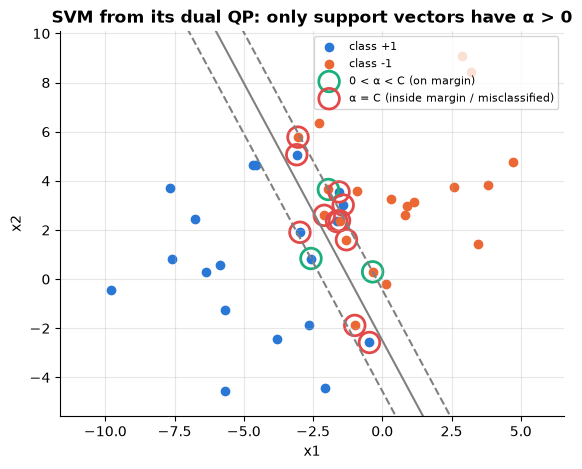

26 points have alpha = 0, 3 are on the margin, 11 have alpha = C


In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
xx = np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 200)
for off, ls in [(0, "-"), (1, "--"), (-1, "--")]:
    ax.plot(xx, (off - b_dual - w_dual[0] * xx) / w_dual[1], ls, color="gray", lw=1.5)   # w.x + b = off
ax.scatter(*Xs[ys > 0].T, color=PALETTE[0], label="class +1")
ax.scatter(*Xs[ys < 0].T, color=PALETTE[1], label="class -1")
at_C = alpha > C_svm - 1e-5
ax.scatter(*Xs[on_margin].T, s=220, facecolors="none", edgecolors=PALETTE[2], lw=2, label="0 < α < C (on margin)")
ax.scatter(*Xs[at_C].T, s=220, facecolors="none", edgecolors=PALETTE[7], lw=2, label="α = C (inside margin / misclassified)")
ax.set_ylim(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("SVM from its dual QP: only support vectors have α > 0")
ax.legend(fontsize=8); plt.show()
print(f"{(alpha < 1e-5).sum()} points have alpha = 0, {on_margin.sum()} are on the margin, {at_C.sum()} have alpha = C")

**What just happened?** Solving the dual QP with a general-purpose solver reproduced scikit-learn's `SVC` exactly: the same $w$ and $b$, the same 14 support vectors, and the same $\alpha_i y_i$ values (sklearn calls them `dual_coef_`). The primal and dual objective values agree (zero duality gap). The classes overlap, so all three groups appear: 26 points have $\alpha_i = 0$ and could be deleted without changing the classifier, 3 sit exactly on the dashed margin lines, and 11 have $\alpha_i = C$ (inside the margin or on the wrong side).

**Complexity:** the dual has $n$ variables and an $n \times n$ matrix $Q$, so generic QP solvers cost $O(n^3)$. libsvm (inside `SVC`) uses **SMO**, which updates two $\alpha$'s at a time analytically and costs roughly $O(n^2)$ to $O(n^3)$ in practice. This is why kernel SVMs struggle beyond about $10^5$ samples.

## 6. Projected gradient descent

Projected gradient descent takes a normal downhill step, and if that step leaves the allowed region, snaps back to the nearest allowed point.

For $\min_{x \in C} f(x)$ with $C$ a closed convex set:

$$x_{k+1} = \Pi_C\big(x_k - \eta \nabla f(x_k)\big), \qquad \Pi_C(z) = \arg\min_{x \in C} \lVert x - z \rVert_2.$$

The **projection** $\Pi_C$ is unique when $C$ is convex. The method is useful when projecting is cheap:

| Set $C$ | Projection |
|---|---|
| box $l \le x \le u$ | `clip(z, l, u)` |
| non-negative orthant $x \ge 0$ | `max(z, 0)` |
| $\ell_2$ ball of radius $r$ | $z \cdot \min(1, r / \lVert z\rVert)$ |
| probability simplex $\{x \ge 0, \sum x = 1\}$ | sort-based algorithm, $O(n \log n)$ (Duchi et al., 2008) |

With step $\eta = 1/L$ ($L$ is the Lipschitz constant of $\nabla f$), projected GD has the same $O(1/k)$ rate on convex problems as plain GD.

**Simplex projection, worked by hand:** project $z = (0.8, 0.6, -0.2)$. We need $x_i = \max(z_i - \tau, 0)$ with $\sum x_i = 1$. Try keeping the two largest coordinates: $(0.8 - \tau) + (0.6 - \tau) = 1 \Rightarrow \tau = 0.2$, giving $x = (0.6, 0.4, 0)$. This is consistent, because $z_3 - \tau = -0.4 < 0$.

hand example: [0.6 0.4 0. ]
simplex projection matches SLSQP on 5 random vectors
NNLS  projected GD: [1.0567 0.0284 1.9934 0.0244 0.     2.9223 0.     0.465 ]
NNLS  scipy nnls  : [1.0567 0.0284 1.9934 0.0244 0.     2.9223 0.     0.465 ]
mixture weights (projected GD): [0.5001 0.3015 0.1984 0.    ]  sum = 1.0


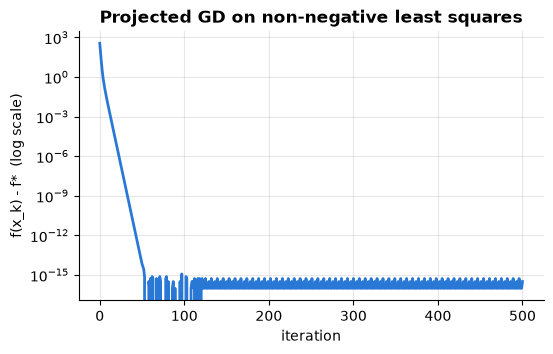

In [14]:
def project_simplex(z):
    """Euclidean projection onto {x >= 0, sum x = 1} (Duchi et al. 2008), O(n log n)."""
    u = np.sort(z)[::-1]                         # sort descending
    css = np.cumsum(u)
    k = np.arange(1, len(z) + 1)
    rho = np.nonzero(u - (css - 1) / k > 0)[0][-1]   # last index that stays positive
    tau = (css[rho] - 1) / (rho + 1)
    return np.maximum(z - tau, 0)

print("hand example:", project_simplex(np.array([0.8, 0.6, -0.2])))

# check against a generic constrained solver on random vectors
for t in range(5):
    z = np.random.default_rng(t).normal(size=6) * 2
    ref = minimize(lambda x: ((x - z) ** 2).sum(), np.ones(6) / 6, method="SLSQP", bounds=[(0, None)] * 6,
                   constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1}], options={"ftol": 1e-14}).x
    assert np.allclose(project_simplex(z), ref, atol=1e-5)
print("simplex projection matches SLSQP on 5 random vectors")

def projected_gd(grad, project, x0, L, iters):
    """x_{k+1} = Proj(x_k - grad/L). Returns the final x and the iterate history."""
    x, hist = x0.copy(), [x0.copy()]
    for _ in range(iters):
        x = project(x - grad(x) / L)
        hist.append(x.copy())
    return x, np.array(hist)

# Problem 1: non-negative least squares  min ||Ax - b||^2 / 2  s.t.  x >= 0
A_nn = rng.normal(size=(50, 8)); b_nn = A_nn @ np.array([1, 0, 2, 0, 0, 3, 0, 0.5]) + 0.3 * rng.normal(size=50)
L_nn = np.linalg.eigvalsh(A_nn.T @ A_nn).max()
x_pgd, hist_nn = projected_gd(lambda x: A_nn.T @ (A_nn @ x - b_nn), lambda z: np.maximum(z, 0), np.zeros(8), L_nn, 500)
x_ref, _ = nnls(A_nn, b_nn)
print("NNLS  projected GD:", x_pgd.round(4))
print("NNLS  scipy nnls  :", x_ref.round(4))

# Problem 2: mixture weights  min ||M w - target||^2 / 2  s.t. w in the simplex
M_mix = np.abs(rng.normal(size=(30, 4))); w_true = np.array([0.5, 0.3, 0.2, 0.0])
t_mix = M_mix @ w_true + 0.01 * rng.normal(size=30)
L_mix = np.linalg.eigvalsh(M_mix.T @ M_mix).max()
w_pgd, hist_mix = projected_gd(lambda w: M_mix.T @ (M_mix @ w - t_mix), project_simplex, np.ones(4) / 4, L_mix, 2000)
print("mixture weights (projected GD):", w_pgd.round(4), " sum =", round(w_pgd.sum(), 6))

f_nn = lambda x: 0.5 * np.sum((A_nn @ x - b_nn) ** 2)
plt.figure(figsize=(6, 3.5))
plt.semilogy([f_nn(x) - f_nn(x_ref) + 1e-16 for x in hist_nn])
plt.xlabel("iteration"); plt.ylabel("f(x_k) - f*  (log scale)"); plt.title("Projected GD on non-negative least squares")
plt.show()
assert np.allclose(x_pgd, x_ref, atol=1e-4)

**What just happened?** The sort-based projection reproduced the hand example $(0.6, 0.4, 0)$ and matched a generic solver. Projected GD then solved non-negative least squares to the same answer as scipy's specialised `nnls`, with several coordinates exactly zero, held there by the projection. It also recovered mixture weights that lie on the simplex. The suboptimality falls linearly on the log plot because this least-squares objective is *strongly* convex, which gives a faster, geometric rate than the general $O(1/k)$.

⚠️ **Common mistake:** projecting onto each constraint separately, e.g. "clip to $\ge 0$, then rescale to sum to 1". That gives a point in the simplex, but not the *nearest* one, so the convergence guarantee is lost. For example, $(0.8, 0.6, -0.2)$ clipped and rescaled is $(0.571, 0.429, 0)$, not $(0.6, 0.4, 0)$.

## 7. Proximal gradient: ISTA and FISTA for Lasso

Proximal gradient handles a smooth part with a gradient step and a "spiky" part (like $|w|$) with an exact mini-problem that has a closed-form answer.

The Lasso objective (scikit-learn's scaling) is

$$F(w) = \underbrace{\tfrac{1}{2n}\lVert Xw - y\rVert_2^2}_{f(w)\text{: smooth}} + \underbrace{\alpha \lVert w \rVert_1}_{g(w)\text{: convex, not differentiable at } 0}.$$

The **proximal operator** of $g$ with step $t$ is

$$\operatorname{prox}_{t g}(v) = \arg\min_w \Big( g(w) + \tfrac{1}{2t}\lVert w - v \rVert^2 \Big).$$

For $g = \alpha\lVert\cdot\rVert_1$ it separates by coordinate and gives **soft-thresholding**: $S_{t\alpha}(v)_i = \operatorname{sign}(v_i)\max(|v_i| - t\alpha, 0)$.

Hand example: with $t\alpha = 1$, $S(3) = 2$, $S(0.4) = 0$, $S(-2.5) = -1.5$. Small values become **exactly zero**, which is why Lasso selects features.

The algorithms:
- **ISTA** (iterative shrinkage-thresholding): $w_{k+1} = S_{\alpha/L}\big(w_k - \tfrac1L \nabla f(w_k)\big)$. Convergence rate $F(w_k) - F^\star = O(1/k)$.
- **FISTA** (Beck & Teboulle, 2009) adds Nesterov momentum:

$$w_{k} = S_{\alpha/L}\big(v_k - \tfrac1L\nabla f(v_k)\big),\quad t_{k+1} = \tfrac{1 + \sqrt{1 + 4t_k^2}}{2},\quad v_{k+1} = w_k + \tfrac{t_k - 1}{t_{k+1}}(w_k - w_{k-1}).$$

It reaches $O(1/k^2)$, which is optimal for first-order methods on this problem class. Projected GD is the special case where $g$ is the indicator function of $C$ (0 inside, $+\infty$ outside), whose prox is the projection.

soft-thresholding hand example: [ 2.   0.  -1.5]
condition number of X^T X / n: 1082
max |w_FISTA - w_sklearn| = 6.5e-04
non-zero coefficients (FISTA): [0, 3, 6, 7, 8, 9, 10, 12, 20, 23, 27]  true support: [0, 3, 7, 12, 20]
iter   10:  ISTA gap = 6.22e-01   FISTA gap = 4.94e-01
iter  100:  ISTA gap = 1.65e-01   FISTA gap = 1.65e-03
iter  300:  ISTA gap = 4.08e-02   FISTA gap = 2.03e-06
iter 1000:  ISTA gap = 1.93e-03   FISTA gap = 2.00e-08


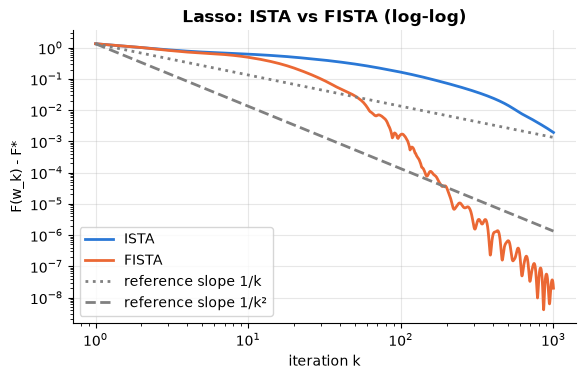

In [15]:
def soft_threshold(v, thr):
    """prox of thr*||.||_1: shrink every coordinate towards 0 by thr, clamp at 0."""
    return np.sign(v) * np.maximum(np.abs(v) - thr, 0.0)

print("soft-thresholding hand example:", soft_threshold(np.array([3.0, 0.4, -2.5]), 1.0))

# synthetic sparse regression: 30 features, only 5 truly matter.
# Neighbouring features are strongly correlated (corr = 0.95^|i-j|), which makes the problem
# ill-conditioned: exactly the situation where first-order methods are slow.
n_l, d_l = 200, 30
corr_l = 0.95 ** np.abs(np.subtract.outer(np.arange(d_l), np.arange(d_l)))
X_l = rng.normal(size=(n_l, d_l)) @ np.linalg.cholesky(corr_l).T
w_true_l = np.zeros(d_l); w_true_l[[0, 3, 7, 12, 20]] = [3.0, -2.0, 1.5, 1.0, -0.8]
y_l = X_l @ w_true_l + 0.5 * rng.normal(size=n_l)
alpha_l = 0.02

lasso_obj = lambda w: 0.5 / n_l * np.sum((X_l @ w - y_l) ** 2) + alpha_l * np.abs(w).sum()
grad_f = lambda w: X_l.T @ (X_l @ w - y_l) / n_l
eig_l = np.linalg.eigvalsh(X_l.T @ X_l / n_l)
L_l = eig_l.max()                                            # Lipschitz constant of grad f
print(f"condition number of X^T X / n: {eig_l.max() / eig_l.min():.0f}")

def ista(iters):
    w, hist = np.zeros(d_l), []
    for _ in range(iters):
        w = soft_threshold(w - grad_f(w) / L_l, alpha_l / L_l)
        hist.append(lasso_obj(w))
    return w, hist

def fista(iters):
    w = w_prev = np.zeros(d_l); v = w.copy(); t = 1.0; hist = []
    for _ in range(iters):
        w = soft_threshold(v - grad_f(v) / L_l, alpha_l / L_l)   # prox-gradient step at v
        t_next = (1 + np.sqrt(1 + 4 * t * t)) / 2
        v = w + (t - 1) / t_next * (w - w_prev)                 # momentum extrapolation
        w_prev, t = w, t_next
        hist.append(lasso_obj(w))
    return w, hist

K_IT = 1000
w_ista, h_ista = ista(K_IT)
w_fista, h_fista = fista(K_IT)
sk = Lasso(alpha=alpha_l, fit_intercept=False, tol=1e-14, max_iter=100000).fit(X_l, y_l)
F_star = lasso_obj(sk.coef_)
print("max |w_FISTA - w_sklearn| =", f"{np.abs(w_fista - sk.coef_).max():.1e}")
print("non-zero coefficients (FISTA):", np.nonzero(np.abs(w_fista) > 1e-6)[0].tolist(), " true support: [0, 3, 7, 12, 20]")
for k in [10, 100, 300, 1000]:
    print(f"iter {k:4d}:  ISTA gap = {max(h_ista[k-1] - F_star, 0):.2e}   FISTA gap = {max(h_fista[k-1] - F_star, 0):.2e}")

plt.figure(figsize=(6.5, 3.8))
ks = np.arange(1, K_IT + 1)
plt.loglog(ks, np.maximum(np.array(h_ista) - F_star, 1e-16), label="ISTA")
plt.loglog(ks, np.maximum(np.array(h_fista) - F_star, 1e-16), label="FISTA")
plt.loglog(ks, (h_ista[0] - F_star) / ks, ":", color="gray", label="reference slope 1/k")
plt.loglog(ks, (h_fista[0] - F_star) / ks**2, "--", color="gray", label="reference slope 1/k²")
plt.xlabel("iteration k"); plt.ylabel("F(w_k) - F*"); plt.title("Lasso: ISTA vs FISTA (log-log)"); plt.legend()
plt.show()
assert np.abs(w_fista - sk.coef_).max() < 1e-3

**What just happened?** The correlated features make the problem ill-conditioned (condition number about 1,000). After 100 iterations, FISTA's objective gap is about 100 times smaller than ISTA's; after 1,000 iterations it is about 100,000 times smaller. On the log-log plot, ISTA roughly follows the $1/k$ reference line and FISTA the much steeper $1/k^2$ line, as the theory predicts. (FISTA's objective is not monotone: the wiggles on its curve are normal.) FISTA's coefficients agree with scikit-learn's to within $10^{-3}$.

The non-zero set contains the five true features plus a few small extras: with correlation 0.95, neighbouring features carry almost the same information, and Lasso spreads some weight onto them. This is a known weakness of Lasso with correlated features, and the reason the **elastic net** (practice problem 3) exists.

**Complexity:** each ISTA/FISTA iteration costs one gradient, $O(nd)$, plus an $O(d)$ soft-threshold. Iterations needed for accuracy $\varepsilon$: $O(L/\varepsilon)$ for ISTA and $O(\sqrt{L/\varepsilon})$ for FISTA. scikit-learn's `Lasso` uses **coordinate descent** instead, which is often faster in practice for Lasso.

## 8. ADMM: Lasso and consensus (distributed) optimisation

ADMM splits a hard problem into two easy pieces, solves them in turn, and uses a running "disagreement penalty" to force the pieces to agree.

The **alternating direction method of multipliers** (ADMM) solves $\min f(x) + g(z)$ s.t. $x - z = 0$ (more generally $Ax + Bz = c$) using the **augmented Lagrangian**, the Lagrangian plus a penalty $\tfrac\rho2 \lVert x - z\rVert^2$. In scaled form (with $u = \nu/\rho$):

$$x^{k+1} = \arg\min_x f(x) + \tfrac\rho2\lVert x - z^k + u^k\rVert^2,\quad z^{k+1} = \operatorname{prox}_{g/\rho}(x^{k+1} + u^k),\quad u^{k+1} = u^k + x^{k+1} - z^{k+1}.$$

For Lasso, $f(x) = \tfrac{1}{2n}\lVert Xx - y\rVert^2$, so the $x$-step is a ridge-like linear solve $(X^\top X/n + \rho I)\,x = X^\top y/n + \rho(z - u)$. The matrix never changes, so we factorise it once. The $z$-step is soft-thresholding. Progress is monitored with the **primal residual** $r = \lVert x - z\rVert$ and the **dual residual** $s = \rho\lVert z^{k+1} - z^k\rVert$; both go to zero.

**Consensus ADMM.** Split the data across $K$ workers (hospitals, phones, data centres). Each worker $k$ keeps its own copy $x_k$, and we require $x_k = z$ for all $k$:

$$\min \sum_{k=1}^K f_k(x_k) + g(z)\quad \text{s.t.}\; x_k = z.$$

Each worker solves a small local problem on **its own data only**. The coordinator averages $x_k + u_k$ and applies the prox of $g$. Raw data never leave the workers, which is the mathematical skeleton of **federated learning** ([`15_MLOps/09_federated_learning`](../15_MLOps/09_federated_learning/01_federated_learning.ipynb)).

max |z_ADMM - w_sklearn| = 1.5e-06
max |z_consensus - w_sklearn| = 2.0e-08


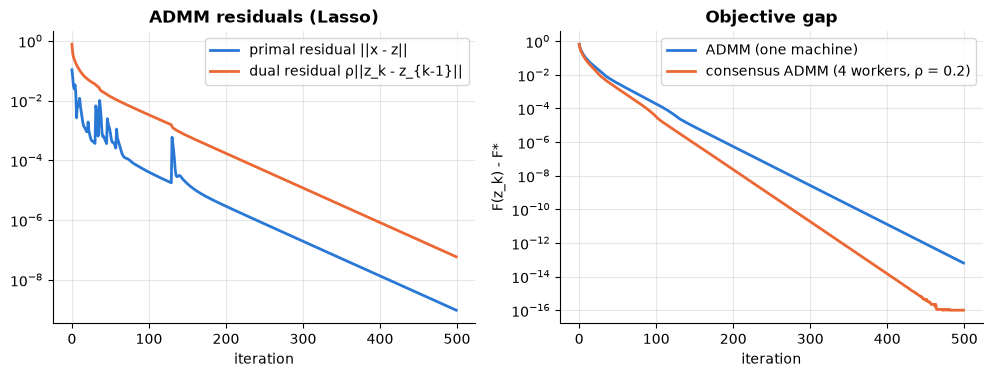

In [16]:
def admm_lasso(X, y, alpha, rho=1.0, iters=300):
    n, d = X.shape
    Lchol = np.linalg.cholesky(X.T @ X / n + rho * np.eye(d))   # factorise once: O(d^3)
    Xty = X.T @ y / n
    x = z = u = np.zeros(d); hist = []
    for _ in range(iters):
        rhs = Xty + rho * (z - u)
        x = np.linalg.solve(Lchol.T, np.linalg.solve(Lchol, rhs))   # two triangular solves
        z_old = z
        z = soft_threshold(x + u, alpha / rho)                      # prox of the L1 term
        u = u + x - z                                               # running disagreement
        hist.append((np.linalg.norm(x - z), rho * np.linalg.norm(z - z_old), lasso_obj(z) - F_star))
    return z, np.array(hist)

z_admm, h_admm = admm_lasso(X_l, y_l, alpha_l, iters=500)
print("max |z_ADMM - w_sklearn| =", f"{np.abs(z_admm - sk.coef_).max():.1e}")

def consensus_admm_lasso(X_parts, y_parts, alpha, n_total, rho=1.0, iters=300):
    """Each worker k only touches (X_k, y_k). Objective: sum_k ||X_k x_k - y_k||^2/(2n) + alpha||z||_1."""
    K, d = len(X_parts), X_parts[0].shape[1]
    facts = [np.linalg.cholesky(Xk.T @ Xk / n_total + rho * np.eye(d)) for Xk in X_parts]
    xs_ = [np.zeros(d) for _ in range(K)]; us = [np.zeros(d) for _ in range(K)]; z = np.zeros(d)
    gaps = []
    for _ in range(iters):
        for k in range(K):                                           # local work (in parallel in practice)
            rhs = X_parts[k].T @ y_parts[k] / n_total + rho * (z - us[k])
            xs_[k] = np.linalg.solve(facts[k].T, np.linalg.solve(facts[k], rhs))
        avg = np.mean([xs_[k] + us[k] for k in range(K)], axis=0)    # coordinator: only sees parameters
        z = soft_threshold(avg, alpha / (K * rho))
        for k in range(K):
            us[k] = us[k] + xs_[k] - z
        gaps.append(lasso_obj(z) - F_star)
    return z, gaps

parts = np.array_split(np.arange(n_l), 4)                           # 4 workers with 50 rows each
z_cons, g_cons = consensus_admm_lasso([X_l[p] for p in parts], [y_l[p] for p in parts], alpha_l, n_l, rho=0.2, iters=500)
print("max |z_consensus - w_sklearn| =", f"{np.abs(z_cons - sk.coef_).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogy(h_admm[:, 0], label="primal residual ||x - z||")
axes[0].semilogy(h_admm[:, 1], label="dual residual ρ||z_k - z_{k-1}||")
axes[0].set_xlabel("iteration"); axes[0].set_title("ADMM residuals (Lasso)"); axes[0].legend()
axes[1].semilogy(np.maximum(h_admm[:, 2], 1e-16), label="ADMM (one machine)")
axes[1].semilogy(np.maximum(g_cons, 1e-16), label="consensus ADMM (4 workers, ρ = 0.2)")
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("F(z_k) - F*"); axes[1].set_title("Objective gap"); axes[1].legend()
plt.show()
assert np.abs(z_cons - sk.coef_).max() < 1e-3

**What just happened?** Plain ADMM and consensus ADMM both reach scikit-learn's Lasso solution. In the consensus version, each of the 4 workers only ever touched its own 50 rows; the coordinator only saw parameter vectors. The two residuals fall together, which is the standard stopping test (stop when both are below a tolerance).

The penalty $\rho$ affects speed but not the answer. For the consensus run we used $\rho = 0.2$; with $\rho = 1$ it still converges, just more slowly on this ill-conditioned data. Practical codes adapt $\rho$ automatically, raising it when the primal residual dominates and lowering it when the dual residual dominates.

**Complexity:** a one-off $O(d^3)$ factorisation, then $O(d^2)$ per iteration for the triangular solves. In general ADMM converges at an $O(1/k)$ rate. It is rarely the fastest method on one machine, but it is very robust to the choice of $\rho$ and it splits naturally across machines.

🎓 **Exam / interview tip:** "What does the dual variable $u$ do in ADMM?" It accumulates the running constraint violation $\sum (x - z)$, like the integral term of a PI controller. That accumulation is what eventually forces $x = z$ exactly, whereas a plain quadratic penalty only makes $x \approx z$.

## 9. Interior-point methods: the barrier method and the central path

Instead of walking along the edges of the allowed region, interior-point methods walk through its middle, kept away from the walls by a "force field" that weakens step by step.

Replace the hard constraints $a_i^\top x \le b_i$ with a **logarithmic barrier** that becomes $+\infty$ at the boundary:

$$\min_x \; t\, c^\top x - \sum_{i=1}^m \log(b_i - a_i^\top x).$$

For each $t > 0$ the minimiser $x^\star(t)$ is strictly inside the feasible region. The curve of minimisers as $t$ grows is the **central path**. A neat duality fact: $\lambda_i = 1/\big(t(b_i - a_i^\top x^\star(t))\big)$ is dual feasible, and the duality gap is exactly $m / t$. So $c^\top x^\star(t) - p^\star \le m/t$, a *certificate* of accuracy.

The **barrier method** is:
1. Start strictly inside.
2. Minimise the barrier function with Newton's method (with a backtracking line search that stays inside).
3. Multiply $t$ by $\mu$ (e.g. 10) and repeat from the current point, until $m/t < \varepsilon$.

Modern **primal-dual interior-point** solvers (HiGHS's IPM, Clarabel, MOSEK, Gurobi's barrier) refine this idea and need about 20–50 Newton steps, almost independently of problem size.

In [17]:
# 2-D LP: minimise c^T x over a hexagon-like polygon {x : A x <= b}
A_lp = np.array([[1, 1], [-1, 2], [-2, -1], [1, -2], [2, 0.5], [0, -1]], dtype=float)
b_lp = np.array([4, 4, 2, 2, 6, 1], dtype=float)
c_lp = np.array([-1.0, -2.0])                     # i.e. maximise x1 + 2 x2

def barrier_method(c, A, b, x0, t0=0.1, mu=10, eps=1e-8):
    m = len(b)
    x, t, path, log = x0.astype(float), t0, [x0.copy()], []
    phi = lambda x, t: t * c @ x - np.sum(np.log(b - A @ x))
    while True:
        for newton_it in range(50):                                   # centering step: Newton
            s = b - A @ x                                             # slacks (must stay > 0)
            g = t * c + A.T @ (1 / s)                                 # gradient of phi
            H = A.T @ np.diag(1 / s**2) @ A                           # Hessian of phi
            dx = -np.linalg.solve(H, g)
            decrement2 = -g @ dx                                      # Newton decrement squared
            if decrement2 / 2 < 1e-10:
                break
            step = 1.0
            while np.any(b - A @ (x + step * dx) <= 0):               # stay strictly feasible
                step *= 0.5
            while phi(x + step * dx, t) > phi(x, t) - 0.25 * step * decrement2:   # Armijo backtracking
                step *= 0.5
            x = x + step * dx
        path.append(x.copy())
        log.append({"t": t, "x1": x[0], "x2": x[1], "c^T x": c @ x, "gap bound m/t": m / t})
        if m / t < eps:
            return x, np.array(path), pd.DataFrame(log)
        t *= mu

x_bar, path, log_bar = barrier_method(c_lp, A_lp, b_lp, x0=np.array([0.0, 0.0]))
ref = linprog(c_lp, A_ub=A_lp, b_ub=b_lp, bounds=[(None, None)] * 2, method="highs")
log_bar["true gap c^T x - p*"] = log_bar["c^T x"] - ref.fun
print("barrier x* =", x_bar.round(6), "   linprog (HiGHS) x* =", ref.x.round(6), "  p* =", ref.fun)
assert (log_bar["true gap c^T x - p*"] <= log_bar["gap bound m/t"] + 1e-9).all()
show = log_bar.copy()
for col, fmt in {"t": "{:.0e}", "x1": "{:.6f}", "x2": "{:.6f}", "c^T x": "{:.6f}",
                 "gap bound m/t": "{:.1e}", "true gap c^T x - p*": "{:.1e}"}.items():
    show[col] = show[col].map(fmt.format)                    # format numbers as text for display
show

barrier x* = [1.333333 2.666667]    linprog (HiGHS) x* = [1.333333 2.666667]   p* = -6.666666666666667


,t,x1,x2,c^T x,gap bound m/t,true gap c^T x - p*
0,1e-01,0.376784,1.123361,-2.623505,6.0e+01,4.0e+00
1,1e+00,1.174495,1.955465,-5.085426,6.0e+00,1.6e+00
2,1e+01,1.369198,2.553283,-6.475764,6.0e-01,1.9e-01
3,1e+02,1.338180,2.654296,-6.646771,6.0e-02,2.0e-02
4,1e+03,1.333832,2.665418,-6.664668,6.0e-03,2.0e-03
5,1e+04,1.333383,2.666542,-6.666467,6.0e-04,2.0e-04
6,1e+05,1.333338,2.666654,-6.666647,6.0e-05,2.0e-05
7,1e+06,1.333334,2.666665,-6.666665,6.0e-06,2.0e-06
8,1e+07,1.333333,2.666667,-6.666666,6.0e-07,2.0e-07
9,1e+08,1.333333,2.666667,-6.666667,6.0e-08,2.0e-08


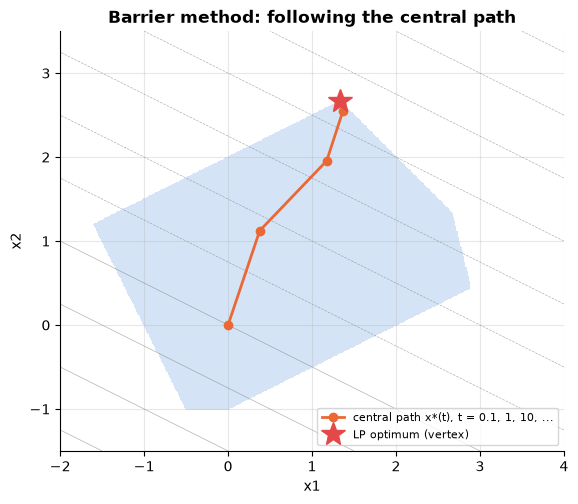

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
g1, g2 = np.meshgrid(np.linspace(-2, 4, 400), np.linspace(-1.5, 3.5, 400))
pts = np.stack([g1.ravel(), g2.ravel()], 1)
feasible = np.all(pts @ A_lp.T <= b_lp, axis=1).reshape(g1.shape)
ax.contourf(g1, g2, feasible, levels=[0.5, 1.5], colors=[PALETTE[0]], alpha=0.2)
ax.contour(g1, g2, c_lp[0] * g1 + c_lp[1] * g2, levels=12, colors="gray", linewidths=0.5, alpha=0.6)
ax.plot(path[:, 0], path[:, 1], "o-", color=PALETTE[1], label="central path x*(t), t = 0.1, 1, 10, ...")
ax.plot(*ref.x, "*", color=PALETTE[7], ms=18, label="LP optimum (vertex)")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Barrier method: following the central path")
ax.legend(fontsize=8, loc="lower right"); ax.set_aspect("equal"); plt.show()

**What just happened?** Starting at the origin (inside the polygon), each Newton centering step moved to $x^\star(t)$ for a larger $t$. The path curves through the interior and approaches the optimal vertex found by HiGHS. The table confirms the theory: the true gap $c^\top x - p^\star$ is always below the bound $m/t$ (here $m = 6$). In fact it is close to $2/t$: only 2 of the 6 constraints are active at the optimum, and the multipliers of the 4 inactive ones shrink to zero, so they contribute almost nothing to the real gap. Each tenfold increase of $t$ shrinks the guaranteed gap tenfold, so 10 outer steps give about 10 digits of accuracy.

**Simplex vs interior point:** simplex walks along edges from vertex to vertex (exponential in the worst case, often fast in practice). Interior-point methods cut through the middle and have polynomial worst-case bounds of $O(\sqrt{m}\log(1/\varepsilon))$ Newton steps. Solvers use both: interior point for big problems, simplex to "clean up" to an exact vertex.

## 10. Applications: fairness constraints, portfolios, and why deep learning is non-convex

These examples show convex optimisation at work in AI, and one case where it stops applying.

### 10.1 A fairness constraint as a convex constraint

Zafar et al. (2017) proposed training a logistic regression while bounding the **covariance between the sensitive attribute $s$ and the signed distance to the decision boundary**:

$$\Big|\tfrac1n \sum_i (s_i - \bar s)\, \theta^\top x_i\Big| \le c.$$

This constraint is linear in $\theta$, so "logistic loss + this constraint" is still a convex problem. Shrinking $c$ trades accuracy for a smaller **demographic parity difference** $|P(\hat y = 1 \mid s = 1) - P(\hat y = 1 \mid s = 0)|$. See [`19_AI_Ethics_and_Safety/01_bias_fairness`](../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb) for the fairness metrics themselves.

In [19]:
# synthetic loan data: feature x1 is correlated with the sensitive attribute s
nf = 2000
s_attr = rng.integers(0, 2, nf)
x1 = rng.normal(loc=1.0 * s_attr, scale=1.0)
x2 = rng.normal(size=nf)
y_f = (x1 + 0.5 * x2 + 0.5 * rng.normal(size=nf) > 0.5).astype(float)
X_f = np.column_stack([np.ones(nf), x1, x2])                 # intercept + two features
s_c = s_attr - s_attr.mean()

def logloss(theta):
    z = X_f @ theta
    return np.mean(np.logaddexp(0, z) - y_f * z)                # numerically stable log(1+e^z) - y z
def logloss_grad(theta):
    p = 1 / (1 + np.exp(-(X_f @ theta)))
    return X_f.T @ (p - y_f) / nf

rows = []
for c_bound in [None, 0.2, 0.1, 0.05, 0.01]:
    cons = [] if c_bound is None else [
        {"type": "ineq", "fun": lambda th, c=c_bound: c - (s_c @ (X_f @ th)) / nf},
        {"type": "ineq", "fun": lambda th, c=c_bound: c + (s_c @ (X_f @ th)) / nf}]
    th = minimize(logloss, np.zeros(3), jac=logloss_grad, constraints=cons, method="SLSQP").x
    pred = (X_f @ th > 0)
    dp = abs(pred[s_attr == 1].mean() - pred[s_attr == 0].mean())
    rows.append({"covariance bound c": "none" if c_bound is None else c_bound,
                 "accuracy": (pred == y_f).mean(), "demographic parity diff": dp,
                 "|cov(s, θᵀx)|": abs(s_c @ (X_f @ th)) / nf})
fair_table = pd.DataFrame(rows).round(3)
fair_table

,covariance bound c,accuracy,demographic parity diff,"|cov(s, θᵀx)|"
0,none,0.880,0.378,0.919
1,0.2,0.850,0.334,0.200
2,0.1,0.780,0.231,0.100
3,0.05,0.708,0.149,0.050
4,0.01,0.628,0.014,0.010


**What just happened?** With no constraint, the model approves one group much more often, because $x_1$ carries information about $s$. Tightening the covariance bound $c$ steadily shrinks the demographic parity difference while accuracy falls, a **trade-off curve** that the business or regulator must choose a point on. Because the problem stays convex, every point on that curve is the true optimum for its constraint level, not an artefact of a lucky initialisation.

### 10.2 A portfolio QP (Markowitz)

Choose weights $w$ for 5 assets: minimise risk $w^\top \Sigma w$ s.t. expected return $\mu^\top w \ge r$, $\sum w = 1$, $w \ge 0$ (no short selling). Sweeping $r$ traces the **efficient frontier**. The same "minimise variance subject to linear constraints" QP appears in ensemble weighting and risk-parity models.

target return 8.5%:  brute-force KKT weights [0.0221 0.2723 0.3439 0.2251 0.1366] 
                     SLSQP weights           [0.0221 0.2723 0.3439 0.2251 0.1366]
shadow price of the return constraint: 0.318 (extra variance per unit of extra required return)


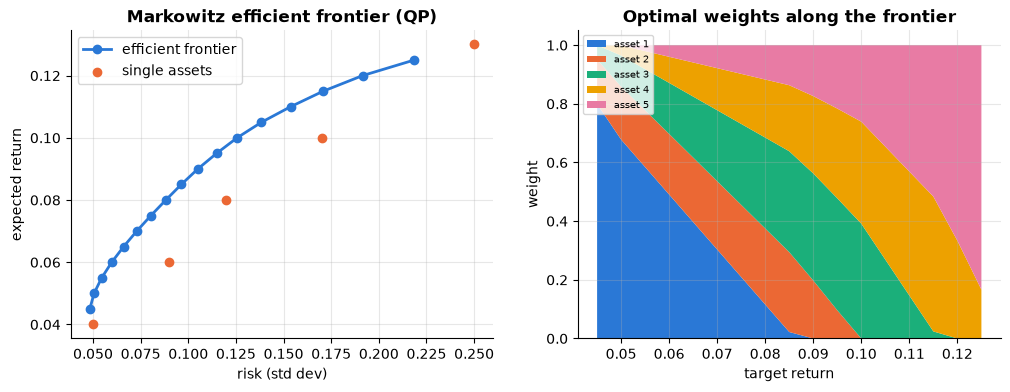

In [20]:
mu_a = np.array([0.04, 0.06, 0.08, 0.10, 0.13])                    # expected annual returns
vol = np.array([0.05, 0.09, 0.12, 0.17, 0.25])                     # volatilities
corr = 0.3 * np.ones((5, 5)) + 0.7 * np.eye(5)
Sigma = np.outer(vol, vol) * corr                                  # covariance matrix (PSD)

frontier = []
for r_target in np.linspace(0.045, 0.125, 17):
    # inequality form G w <= h:  -mu^T w <= -r  and  -w <= 0;  equality: sum w = 1
    G = np.vstack([-mu_a, -np.eye(5)]); h = np.concatenate([[-r_target], np.zeros(5)])
    w, lam, nu = qp_active_set_bruteforce(2 * Sigma, np.zeros(5), G, h, A=np.ones((1, 5)), b=[1.0])
    frontier.append((np.sqrt(w @ Sigma @ w), r_target, lam[0], w))
r_mid = 0.085
w_slsqp = minimize(lambda w: w @ Sigma @ w, np.ones(5) / 5, method="SLSQP", bounds=[(0, None)] * 5,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                {"type": "ineq", "fun": lambda w: mu_a @ w - r_mid}], options={"ftol": 1e-14}).x
G = np.vstack([-mu_a, -np.eye(5)]); h = np.concatenate([[-r_mid], np.zeros(5)])
w_bf, lam_bf, _ = qp_active_set_bruteforce(2 * Sigma, np.zeros(5), G, h, A=np.ones((1, 5)), b=[1.0])
print("target return 8.5%:  brute-force KKT weights", w_bf.round(4), "\n                     SLSQP weights          ", w_slsqp.round(4))
print(f"shadow price of the return constraint: {lam_bf[0]:.3f} (extra variance per unit of extra required return)")
assert np.allclose(w_bf, w_slsqp, atol=1e-4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([f[0] for f in frontier], [f[1] for f in frontier], "o-", label="efficient frontier")
axes[0].scatter(vol, mu_a, color=PALETTE[1], zorder=3, label="single assets")
axes[0].set_xlabel("risk (std dev)"); axes[0].set_ylabel("expected return"); axes[0].set_title("Markowitz efficient frontier (QP)")
axes[0].legend()
W = np.array([f[3] for f in frontier])
axes[1].stackplot([f[1] for f in frontier], W.T, labels=[f"asset {i+1}" for i in range(5)], colors=PALETTE[:5])
axes[1].set_xlabel("target return"); axes[1].set_ylabel("weight"); axes[1].set_title("Optimal weights along the frontier")
axes[1].legend(fontsize=7, loc="upper left"); plt.show()

**What just happened?** Our brute-force KKT solver (now with an equality constraint) and SLSQP agree on the optimal portfolio. The frontier bends: diversification lets low-return targets reach *less* risk than the safest single asset. The weights shift smoothly from safe to risky assets as the target rises, and individual assets drop to exactly 0 when their non-negativity constraint becomes active. The multiplier of the return constraint is the marginal variance cost of demanding more return: a shadow price, exactly as in Section 3.

### 10.3 Why deep learning is not convex: a symmetry argument

Take a network with two hidden units, $f(x) = v_1 \tanh(w_1 x + b_1) + v_2 \tanh(w_2 x + b_2)$. Swapping the two hidden units gives a *different* parameter vector $\theta'$ with *exactly the same* function and loss. If the loss were convex, the midpoint $\tfrac12(\theta + \theta')$ would need a loss $\le$ the average of the two, i.e. $\le$ the minimum. But at the midpoint both hidden units are identical, so the network effectively has one unit and fits worse. A network with $h$ hidden units has $h!$ such equivalent minima, so the loss surface must have many valleys.

loss(theta) = 0.0019, loss(theta_swapped) = 0.0019, loss(midpoint) = 17.6515


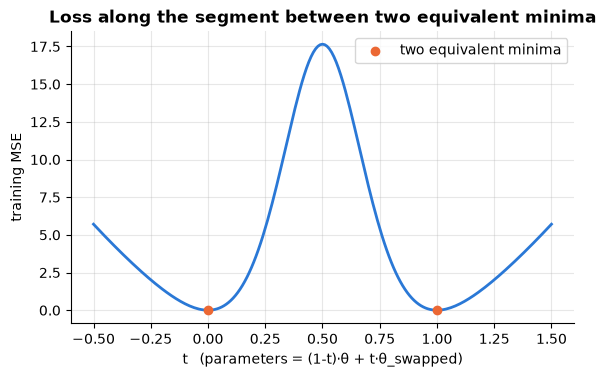

In [21]:
xd = np.linspace(-3, 3, 60); yd = np.sin(1.5 * xd) + 0.3 * xd       # 1-D regression target
def net(theta, x):
    w1, b1, v1, w2, b2, v2 = theta
    return v1 * np.tanh(w1 * x + b1) + v2 * np.tanh(w2 * x + b2)
mse = lambda th: np.mean((net(th, xd) - yd) ** 2)
theta = minimize(mse, x0=np.array([1.0, 0.5, 1.0, -0.5, -0.2, 0.5]), method="BFGS").x
theta_swap = np.concatenate([theta[3:], theta[:3]])                 # swap hidden units 1 and 2
ts = np.linspace(-0.5, 1.5, 201)
loss_line = [mse((1 - t) * theta + t * theta_swap) for t in ts]
print(f"loss(theta) = {mse(theta):.4f}, loss(theta_swapped) = {mse(theta_swap):.4f}, "
      f"loss(midpoint) = {mse(0.5 * theta + 0.5 * theta_swap):.4f}")
plt.figure(figsize=(6.5, 3.8))
plt.plot(ts, loss_line)
plt.scatter([0, 1], [mse(theta), mse(theta_swap)], color=PALETTE[1], zorder=3, label="two equivalent minima")
plt.xlabel("t   (parameters = (1-t)·θ + t·θ_swapped)"); plt.ylabel("training MSE")
plt.title("Loss along the segment between two equivalent minima"); plt.legend(); plt.show()

**What just happened?** The two endpoints have identical loss, but the loss at the midpoint is much higher: Jensen's inequality fails, so the training loss is **not convex** in the weights. This is why deep learning uses the stochastic first-order methods of [`06_optimization`](06_optimization.ipynb) with good initialisation, instead of convex solvers with global guarantees. Convex theory still helps there: each *layer* is often convex in its own weights (e.g. the last linear layer with cross-entropy), and many analyses of SGD start from the convex case.

## 11. Summary table of algorithms

> 💬 **In plain English:** one table to choose the right algorithm for a constrained or non-smooth problem.

| Method | Problem it solves | Cost per iteration | Iterations to accuracy ε (convex) | Use it when |
|---|---|---|---|---|
| Gradient descent | smooth, unconstrained | one gradient | $O(1/\varepsilon)$; $O(\log 1/\varepsilon)$ if strongly convex | huge $n$, smooth loss |
| Projected GD | smooth + simple convex set | gradient + projection | $O(1/\varepsilon)$ | box, ball or simplex constraints |
| ISTA (proximal gradient) | smooth + non-smooth $g$ with cheap prox | gradient + prox | $O(1/\varepsilon)$ | Lasso, group Lasso, nuclear norm |
| FISTA | same as ISTA | gradient + prox | $O(1/\sqrt{\varepsilon})$ (optimal first-order rate) | same, when you want speed |
| ADMM | separable $f(x) + g(z)$ with a linear coupling | two sub-solves + update | $O(1/\varepsilon)$ | distributed / federated data, robust default |
| Barrier / interior point | LP, QP, SOCP, SDP with constraints | one Newton step, $O(n^3)$ | $O(\sqrt{m} \log 1/\varepsilon)$ Newton steps | small/medium problems to high accuracy |
| Active set / simplex | LP, QP | linear solve per pivot | exponential worst case, fast in practice | warm starts, exact vertex solutions |
| SMO (inside libsvm) | SVM dual | $O(n)$ per pair update | problem dependent | kernel SVMs |

## 12. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same ideas run inside sparse models, federated learning, safe RL and industrial planners.

- **Sparse models and feature selection:** Lasso, elastic net and group Lasso are solved with the proximal methods of Section 7 (and coordinate descent). The same soft-thresholding step reappears in **compressed sensing** and in sparsity-inducing pruning of neural networks ([`05_Deep_Learning/08_model_compression`](../05_Deep_Learning/08_model_compression.ipynb)).
- **Weight decay and AdamW:** AdamW's "decoupled weight decay" is literally a proximal step for the $\ell_2$ penalty applied after the Adam step ([`06_optimization`](06_optimization.ipynb)).
- **Federated and distributed learning:** consensus ADMM (Section 8) is the textbook ancestor of FedAvg-style algorithms; FedProx adds exactly the proximal term $\tfrac\rho2\lVert x - z\rVert^2$ to each client's objective ([`15_MLOps/09_federated_learning`](../15_MLOps/09_federated_learning/01_federated_learning.ipynb)).
- **Constrained RL and RLHF:** safe RL methods add a Lagrange multiplier for a cost constraint and update it by **dual ascent** (raise the price when the constraint is violated). The KL penalty in RLHF is the Lagrangian form of a trust-region constraint ([`08_LLM/12_alignment_techniques`](../08_LLM/12_alignment_techniques.ipynb)).
- **Optimal transport:** the Sinkhorn algorithm, used in domain adaptation and some generative models, solves an entropy-regularised LP through its dual.
- **Differentiable optimisation layers:** libraries such as cvxpylayers put a convex problem *inside* a neural network and backpropagate through its KKT conditions (used in planning and control).
- **Kernel methods and SVMs** ([`16_learning_theory/02_kernel_methods`](../03_Machine_Learning/16_learning_theory/02_kernel_methods.ipynb)) are convex QPs. Margin-based generalisation bounds ([`16_learning_theory/01`](../03_Machine_Learning/16_learning_theory/01_statistical_learning_theory.ipynb)) come from the same geometry.
- **Portfolio, supply-chain and energy optimisation** in industry are QPs, SOCPs and MILPs solved with interior-point and simplex codes ([`advanced_algorithms/05`](../00_AI_Fundamentals/advanced_algorithms/05_linear_and_integer_programming.ipynb)).

## Recap (key takeaways)

- A problem is **convex** when the objective and inequality constraints are convex and equality constraints are affine. Then **every local minimum is global**.
- Check convexity with the chord (Jensen) test, the PSD-Hessian test, or, most practically, by **composition rules** (sums, affine maps, max).
- **LP ⊂ QP ⊂ SOCP ⊂ SDP** are the standard forms; cvxpy and similar tools recognise them automatically.
- The **dual function** is always concave and always a lower bound (**weak duality**). For convex problems with **Slater's condition**, $d^\star = p^\star$ (**strong duality**). Non-convex problems can have a positive gap, and when Slater fails the dual optimum may not be attained.
- **KKT** = primal feasibility, dual feasibility, complementary slackness, stationarity. For convex problems with Slater's condition it is equivalent to optimality, and the multipliers are the **shadow prices** of the constraints.
- The **SVM dual** is a box-plus-one-equality QP whose non-zero $\alpha_i$ are the support vectors.
- **Projected GD**, **ISTA/FISTA** and **ADMM** handle constraints and non-smooth penalties with cheap iterations. **Barrier/interior-point** methods reach high accuracy in few Newton steps, with a built-in $m/t$ gap certificate.
- Neural-network losses are **non-convex** (permutation symmetry is a simple proof), which is why deep learning relies on SGD rather than convex solvers.

## Practice problems

**1. (Easy, conceptual)** Is $f(x) = \max(x^2, e^x)$ convex? Is $f(x) = \min(x^2, e^x)$?

<details><summary>Show solution</summary>

$\max(x^2, e^x)$ is convex: it is the pointwise maximum of two convex functions. $\min(x^2, e^x)$ is not convex in general; the pointwise minimum does not preserve convexity. Here the two curves cross at $x \approx -0.70$, and the minimum has a "kink pointing up" there: just left of the crossing it follows $e^x$, just right it follows $x^2$, and the slope drops from about $0.50$ to about $-1.41$. A convex function's slope can never decrease.

</details>

**2. (Easy, by hand + code)** Derive the dual of $\min x^2 + y^2$ s.t. $x + y \ge 2$. Find $\lambda^\star$, $d^\star$ and $p^\star$, then check numerically.

<details><summary>Show solution</summary>

$L = x^2 + y^2 + \lambda(2 - x - y)$. Minimising over $x, y$ gives $x = y = \lambda/2$, so $g(\lambda) = \lambda^2/2 + 2\lambda - \lambda^2 = 2\lambda - \lambda^2/2$. Maximising: $\lambda^\star = 2$, $d^\star = 2$. Primal: $x = y = 1$, $p^\star = 2$. The gap is zero, as Slater predicts (e.g. $x = y = 2$ is strictly feasible).

```python
import numpy as np
from scipy.optimize import minimize
# by hand: L = x^2 + y^2 + lam (2 - x - y); x = y = lam/2; g(lam) = 2 lam - lam^2/2; lam* = 2, d* = 2
lams = np.linspace(0, 5, 5001)
g = 2 * lams - lams**2 / 2
res = minimize(lambda z: z @ z, [0, 0], constraints=[{"type": "ineq", "fun": lambda z: z.sum() - 2}], method="SLSQP")
print("d* =", g.max(), "at lambda =", lams[g.argmax()], "| p* =", round(res.fun, 6), "at", res.x.round(6))
```

</details>

**3. (Medium, code)** Write the proximal operator of the elastic-net penalty $\alpha\big(\rho|w| + \tfrac{1 - \rho}{2} w^2\big)$ and verify it against brute-force 1-D minimisation.

<details><summary>Show solution</summary>

The prox minimises $t\alpha(\rho|w| + \tfrac{1-\rho}{2}w^2) + \tfrac12 (w - v)^2$. Setting the subgradient to zero gives "soft-threshold by $t\alpha\rho$, then divide by $1 + t\alpha(1-\rho)$".

```python
import numpy as np
from scipy.optimize import minimize_scalar

def prox_elastic_net(v, t, alpha, l1_ratio):
    """prox of t * alpha * (l1_ratio*|w| + (1-l1_ratio)/2 * w^2): soft-threshold, then shrink."""
    st = np.sign(v) * np.maximum(np.abs(v) - t * alpha * l1_ratio, 0)
    return st / (1 + t * alpha * (1 - l1_ratio))

# check against brute-force 1-D minimisation for many random inputs
r = np.random.default_rng(0)
for _ in range(200):
    v, t, a, l1 = r.normal() * 3, r.uniform(0.1, 2), r.uniform(0.1, 2), r.uniform(0, 1)
    obj = lambda w: t * a * (l1 * abs(w) + (1 - l1) / 2 * w * w) + 0.5 * (w - v) ** 2
    ref = minimize_scalar(obj, bounds=(-20, 20), method="bounded", options={"xatol": 1e-10}).x
    assert abs(prox_elastic_net(v, t, a, l1) - ref) < 1e-5
print("elastic-net prox verified on 200 random cases")
```

</details>

**4. (Medium, code)** Use projected gradient descent to solve least squares with the constraint $\lVert x \rVert_2 \le 2$, and compare with SLSQP.

<details><summary>Show solution</summary>

```python
import numpy as np
from scipy.optimize import minimize

def project_l2_ball(z, r):
    nz = np.linalg.norm(z)
    return z if nz <= r else z * (r / nz)

def pgd_ball_ls(A, b, r, iters=3000):
    L = np.linalg.eigvalsh(A.T @ A).max()
    x = np.zeros(A.shape[1])
    for _ in range(iters):
        x = project_l2_ball(x - A.T @ (A @ x - b) / L, r)
    return x

rng_ = np.random.default_rng(1)
A = rng_.normal(size=(40, 5)); b = A @ np.array([2.0, -1.0, 3.0, 0.5, 1.0]) + 0.1 * rng_.normal(size=40)
x_pgd = pgd_ball_ls(A, b, r=2.0)
ref = minimize(lambda x: 0.5 * np.sum((A @ x - b) ** 2), np.zeros(5), method="SLSQP",
               constraints=[{"type": "ineq", "fun": lambda x: 4.0 - x @ x}], options={"ftol": 1e-14}).x
print("projected GD:", x_pgd.round(5), " norm =", round(np.linalg.norm(x_pgd), 5))
print("SLSQP       :", ref.round(5))
```
The unconstrained solution has norm about 3.9, so the constraint is active and the answer lies on the sphere of radius 2.

</details>

**5. (Medium, exam)** In the soft-margin SVM, what do $\alpha_i = 0$, $0 < \alpha_i < C$ and $\alpha_i = C$ mean geometrically, and which KKT condition tells you? Why does Slater's condition hold for the SVM primal?

<details><summary>Show solution</summary>

From complementary slackness: $\alpha_i[y_i(w^\top x_i + b) - 1 + \xi_i] = 0$ and $\mu_i \xi_i = (C - \alpha_i)\xi_i = 0$.
- $\alpha_i = 0$: the point is correctly classified with margin $\ge 1$, and it does not influence $w$.
- $0 < \alpha_i < C$: then $\xi_i = 0$ and the margin constraint is tight, so the point lies exactly on the margin.
- $\alpha_i = C$: $\xi_i \ge 0$ may be positive, so the point is inside the margin or misclassified.

Slater holds because all constraints are affine in $(w, b, \xi)$, and for affine constraints feasibility is enough (the refined Slater condition). A feasible point always exists: take $w = 0$, $b = 0$, $\xi_i = 1$.

</details>

**6. (Hard, code)** Solve non-negative least squares with ADMM (hint: $g$ is the indicator of $z \ge 0$, whose prox is a projection) and compare with `scipy.optimize.nnls`.

<details><summary>Show solution</summary>

```python
import numpy as np
from scipy.optimize import nnls

def admm_nnls(A, b, rho=1.0, iters=2000):
    """min 1/2||Ax-b||^2 s.t. x >= 0, split as f(x) + indicator(z >= 0), x = z."""
    d = A.shape[1]
    Lc = np.linalg.cholesky(A.T @ A + rho * np.eye(d))
    Atb = A.T @ b
    x = z = u = np.zeros(d)
    for _ in range(iters):
        x = np.linalg.solve(Lc.T, np.linalg.solve(Lc, Atb + rho * (z - u)))
        z = np.maximum(x + u, 0)            # prox of the indicator = projection
        u = u + x - z
    return z

rng_ = np.random.default_rng(2)
A = rng_.normal(size=(60, 6)); b = A @ np.array([1.0, 0, 2.0, 0, 0, 0.7]) + 0.2 * rng_.normal(size=60)
print("ADMM :", admm_nnls(A, b).round(5))
print("nnls :", nnls(A, b)[0].round(5))
```

</details>

**7. (Hard, conceptual)** Explain why the barrier method's duality gap after centering is exactly $m/t$.

<details><summary>Show solution</summary>

At the barrier minimiser $x^\star(t)$, stationarity gives $t c + \sum_i \frac{a_i}{b_i - a_i^\top x} = 0$. Define $\lambda_i = \frac{1}{t(b_i - a_i^\top x^\star(t))} > 0$. Then $c + A^\top \lambda = 0$, so $\lambda$ is dual feasible for the LP dual ($\max -b^\top\lambda$ s.t. $A^\top\lambda + c = 0$, $\lambda \ge 0$). The gap is $c^\top x + b^\top \lambda = -\lambda^\top A x + b^\top\lambda = \sum_i \lambda_i (b_i - a_i^\top x) = \sum_i \frac1t = \frac mt$.

</details>

## Further reading (additional learning resources)

- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press, 2004. Chapters 2–3 (convex sets and functions), 4 (problem forms), 5 (duality and KKT), 11 (interior-point methods). The book is free on the authors' Stanford web page, together with the EE364A lecture slides.
- N. Parikh and S. Boyd, "Proximal Algorithms", *Foundations and Trends in Optimization*, 2014; and S. Boyd et al., "Distributed Optimization and Statistical Learning via the Alternating Direction Method of Multipliers", 2011. Both are free online.
- A. Beck and M. Teboulle, "A Fast Iterative Shrinkage-Thresholding Algorithm for Linear Inverse Problems", *SIAM J. Imaging Sciences*, 2009 (FISTA).
- J. Nocedal and S. Wright, *Numerical Optimization*, 2nd ed., chapters 12 (KKT theory), 16 (QP and active sets) and 19 (interior-point methods).
- M. B. Zafar et al., "Fairness Constraints: Mechanisms for Fair Classification", AISTATS 2017.
- The cvxpy documentation and examples gallery (cvxpy.org) for modelling practice.

## Next notebook

Continue with [`03_Machine_Learning/16_learning_theory/01_statistical_learning_theory.ipynb`](../03_Machine_Learning/16_learning_theory/01_statistical_learning_theory.ipynb). It asks *why* minimising training loss generalises, and uses the margin and regularisation ideas from this notebook as capacity control.